# CE 1110 · Tarea 1: Caracterización espectral y prototipado de filtros

Notebook reproducible de la tarea: genera las señales de prueba, aplica el filtro temporal y la reducción espectral, y calcula métricas y figuras. Debe ejecutarse completo desde el inicio (**Run All**). Las funciones están en `src/` y las pruebas automáticas en `tests/`. El análisis y las interpretaciones están en el informe.

Basado en el notebook `CE1110_generador_tonos_defensa_Kaggle.ipynb` del profesor.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
TESTING = RAIZ / 'resultados' / 'testing'   # tablas de apoyo (no son parte de la entrega mínima)
TESTING.mkdir(parents=True, exist_ok=True)
FIGS = RAIZ / 'resultados' / 'figuras'
FIGS.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / 'src'))
import generacion_senales as gs
import fundamentos_fft as ff

plt.style.use('seaborn-v0_8-whitegrid')
print('Entorno listo. Raíz del proyecto:', RAIZ)

Entorno listo. Raíz del proyecto: /home/fabs/Github/jgarcia_asm_2026_s2


## 1. Fundamentos, muestreo y FFT (tarea 2.1)
Ejemplo numérico de los incisos (b), (c) y (d). Las explicaciones de los incisos (a) y (b) y la interpretación están en el informe.

- **Tono en un bin:** 437.5 Hz = 28·Δf (k = 28).
- **Tono entre bins:** 445.3125 Hz (k = 28.5), el peor caso de fuga.
- **Ventanas:** rectangular y Hann periódica, $w[n] = 0.5 - 0.5\cos(2\pi n/N)$.

In [2]:
CFG_FFT = dict(fs_Hz=16_000, n=1024, f_bin_Hz=437.5, f_entre_Hz=445.3125, fase_grados=35.0)
DF = CFG_FFT['fs_Hz'] / CFG_FFT['n']
assert np.isclose(CFG_FFT['f_bin_Hz'] / DF, round(CFG_FFT['f_bin_Hz'] / DF)), 'f_bin debe caer en un bin'
assert not np.isclose(CFG_FFT['f_entre_Hz'] / DF, round(CFG_FFT['f_entre_Hz'] / DF)), 'f_entre no debe caer en un bin'
print(f"fs = {CFG_FFT['fs_Hz']} Hz, N = {CFG_FFT['n']}, T = N/fs = {1e3 * CFG_FFT['n'] / CFG_FFT['fs_Hz']:.1f} ms, Δf = fs/N = {DF:g} Hz")
print(f"k(f_bin) = {CFG_FFT['f_bin_Hz'] / DF:g}, k(f_entre) = {CFG_FFT['f_entre_Hz'] / DF:g}")

# 2.1(b): resolución, latencia y memoria de un bloque según N (fs fija)
pd.DataFrame([{'N': n_, 'Δf (Hz)': CFG_FFT['fs_Hz'] / n_, 'T = latencia de un bloque (ms)': 1e3 * n_ / CFG_FFT['fs_Hz'],
               'memoria de un bloque float32 (bytes)': 4 * n_} for n_ in (256, 512, 1024, 2048, 4096)]).set_index('N')

fs = 16000 Hz, N = 1024, T = N/fs = 64.0 ms, Δf = fs/N = 15.625 Hz
k(f_bin) = 28, k(f_entre) = 28.5


,Δf (Hz),T = latencia de un bloque (ms),memoria de un bloque float32 (bytes)
N,,,
256,62.50000,16.0,1024
512,31.25000,32.0,2048
1024,15.62500,64.0,4096
2048,7.81250,128.0,8192
4096,3.90625,256.0,16384


### Tono en un bin y entre bins con ventana rectangular y Hann (inciso c)

frecuencia_tono_Hz  bin_dominante  \
tono  ventana                                          
bin   rectangular            437.5000             28   
      hann                   437.5000             28   
entre rectangular            445.3125             28   
      hann                   445.3125             29   

                   frecuencia_bin_dominante_Hz  amplitud_bin_dominante  \
tono  ventana                                                            
bin   rectangular                      437.500                  1.0000   
      hann                             437.500                  1.0000   
entre rectangular                      437.500                  0.6395   
      hann                             453.125                  0.8488   

                   fase_bin_dominante_grados  \
tono  ventana                                  
bin   rectangular                   -55.0000   
      hann                          -55.0000   
entre rectangular                    34.4728   
      hann                         -145.0001   

                   fraccion_energia_fuera_bin_dominante  
tono  ventana                                            
bin   rectangular                                0.0000  
      hann                                       0.3333  
entre rectangular                                0.5910  
      hann                                       0.5197

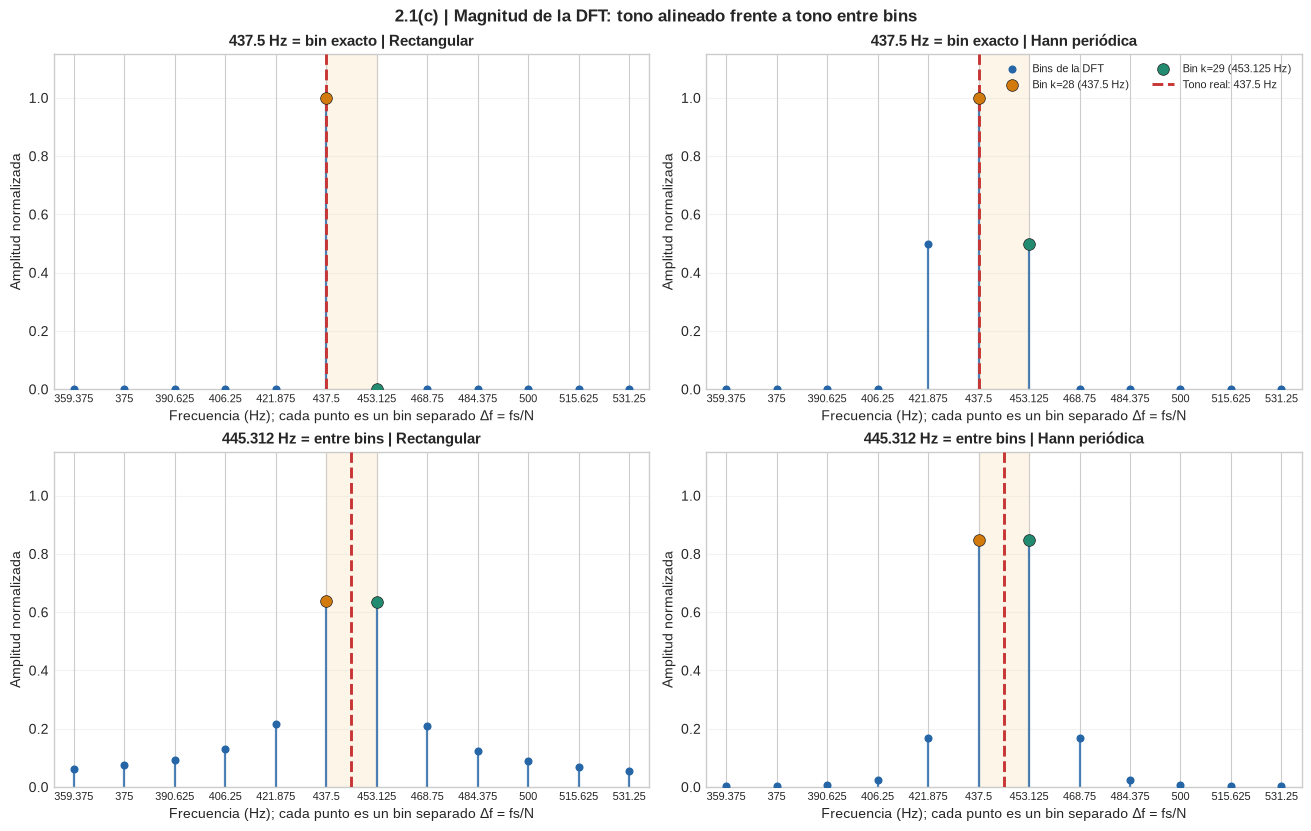

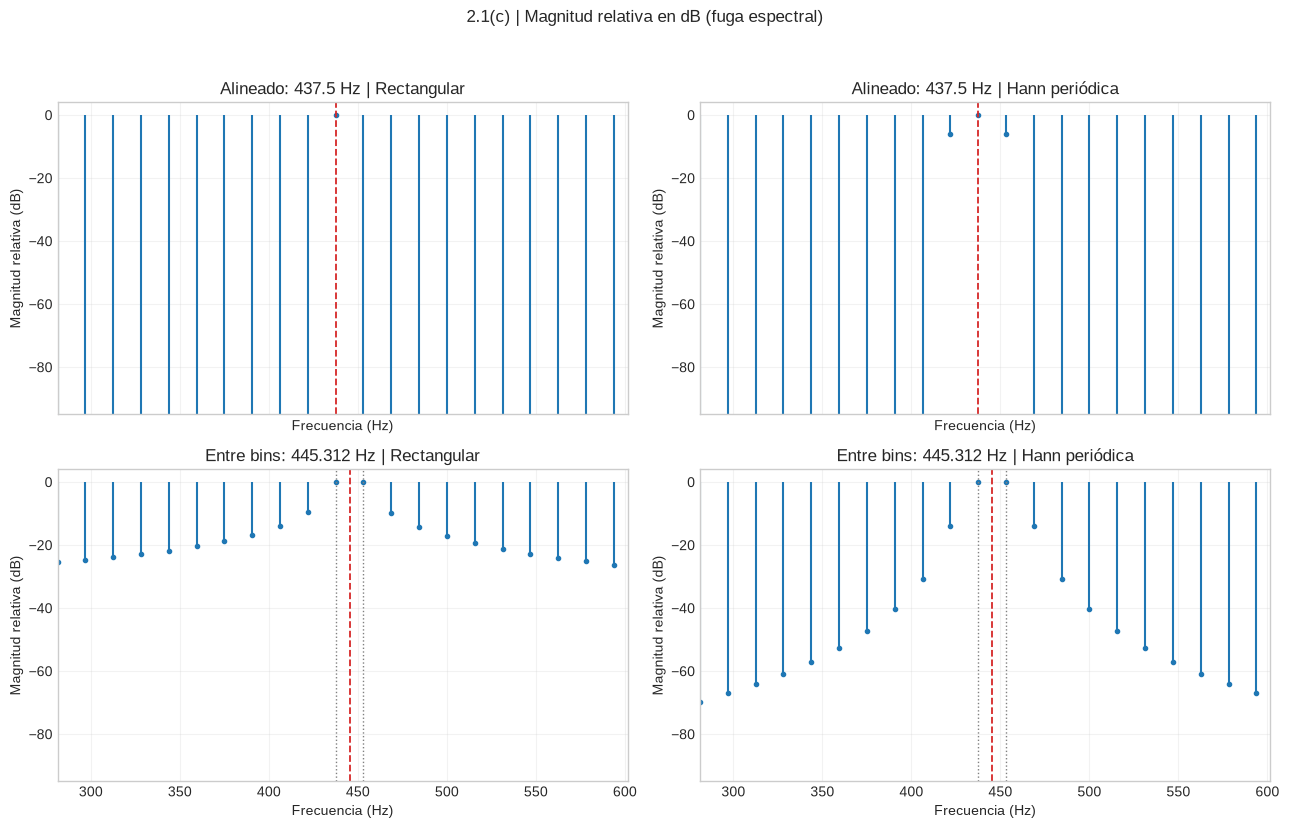

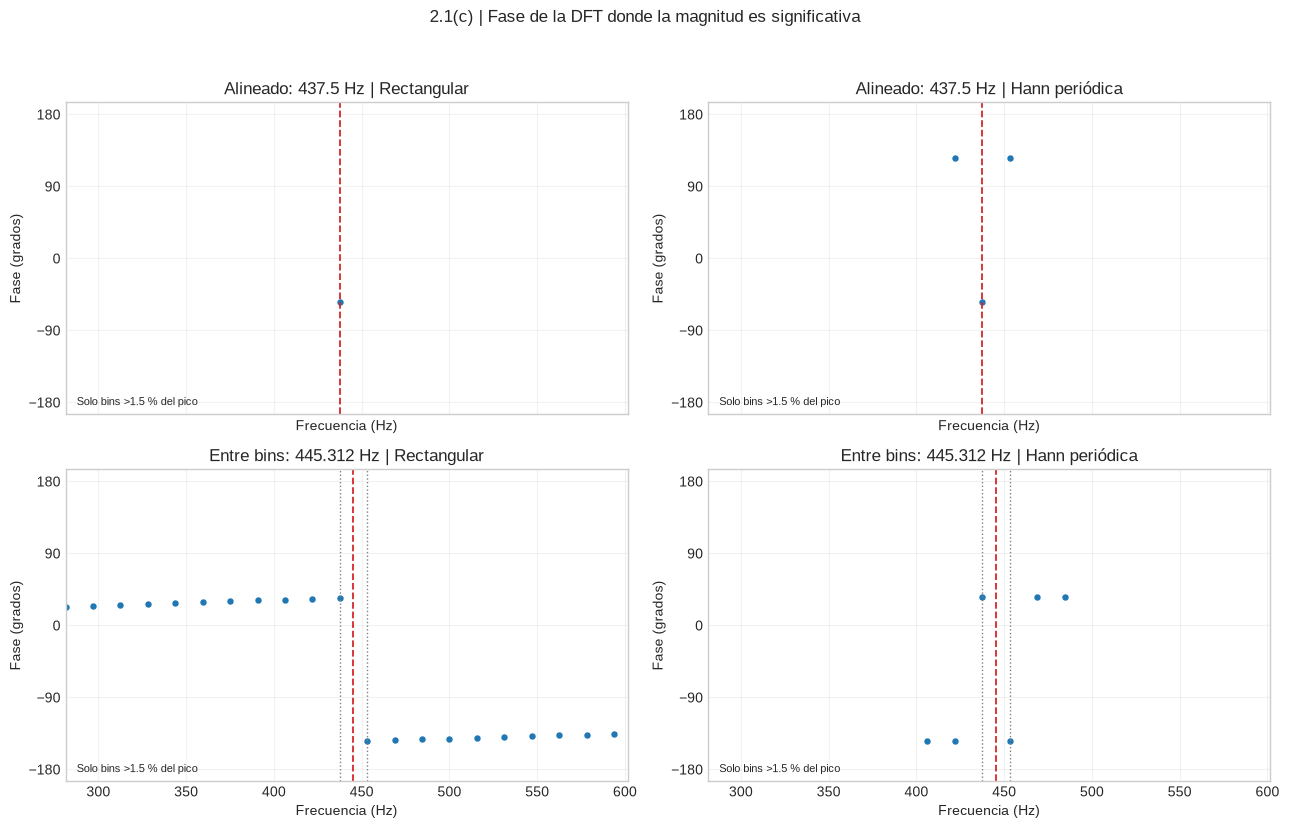

In [3]:
CASOS_FFT, TABLA_FFT = ff.analizar_tonos(CFG_FFT)
display(pd.DataFrame(TABLA_FFT).set_index(['tono', 'ventana']).round(4))

for nombre, fig in [('2_1_magnitud', ff.figura_comparacion_bins(CASOS_FFT, CFG_FFT)),
                    ('2_1_magnitud_dB', ff.espectros_2x2(CASOS_FFT, 'db', CFG_FFT)),
                    ('2_1_fase', ff.espectros_2x2(CASOS_FFT, 'fase', CFG_FFT))]:
    fig.savefig(FIGS / f'{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

### Lóbulo principal y lóbulos laterales de las ventanas (inciso c)

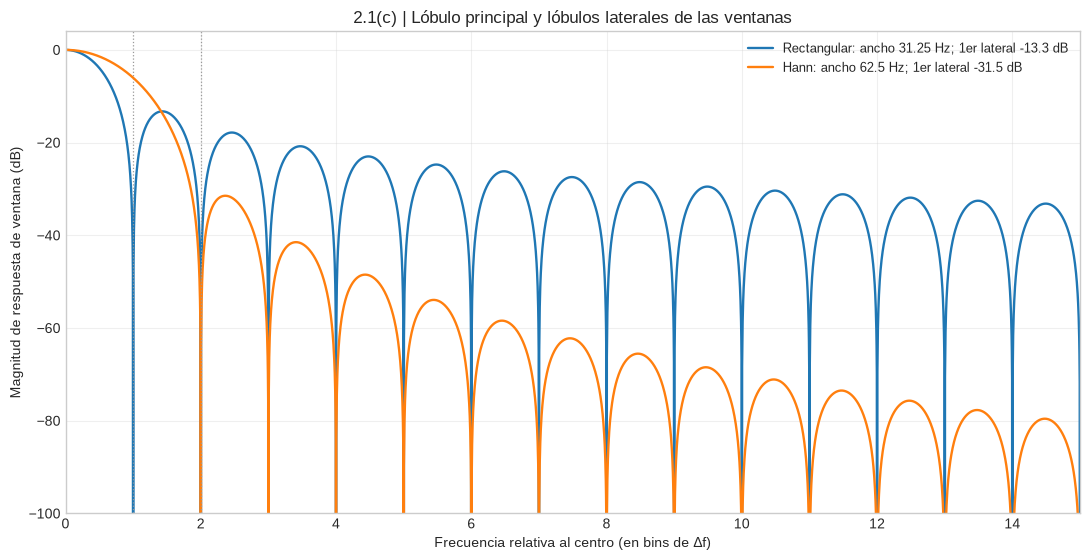

,ancho_lobulo_principal_Hz,ancho_lobulo_principal_bins,primer_lobulo_lateral_dB,frecuencia_primer_lobulo_lateral_Hz
rectangular,31.25,2.0,-13.261,22.338867
hann,62.50,4.0,-31.467,36.926270


In [4]:
fig, MEDIDAS_VENTANAS = ff.medir_ventanas(CFG_FFT['n'], CFG_FFT['fs_Hz'])
fig.savefig(FIGS / '2_1_lobulos_ventanas.png', dpi=150, bbox_inches='tight'); plt.show()
pd.DataFrame(MEDIDAS_VENTANAS).T

### Simetría conjugada y su efecto en la IFFT (inciso d)
Se verifica $X[N-k] = X^*[k]$ en los cuatro casos y se compara anular solo el bin positivo del tono contra anular también su pareja conjugada.

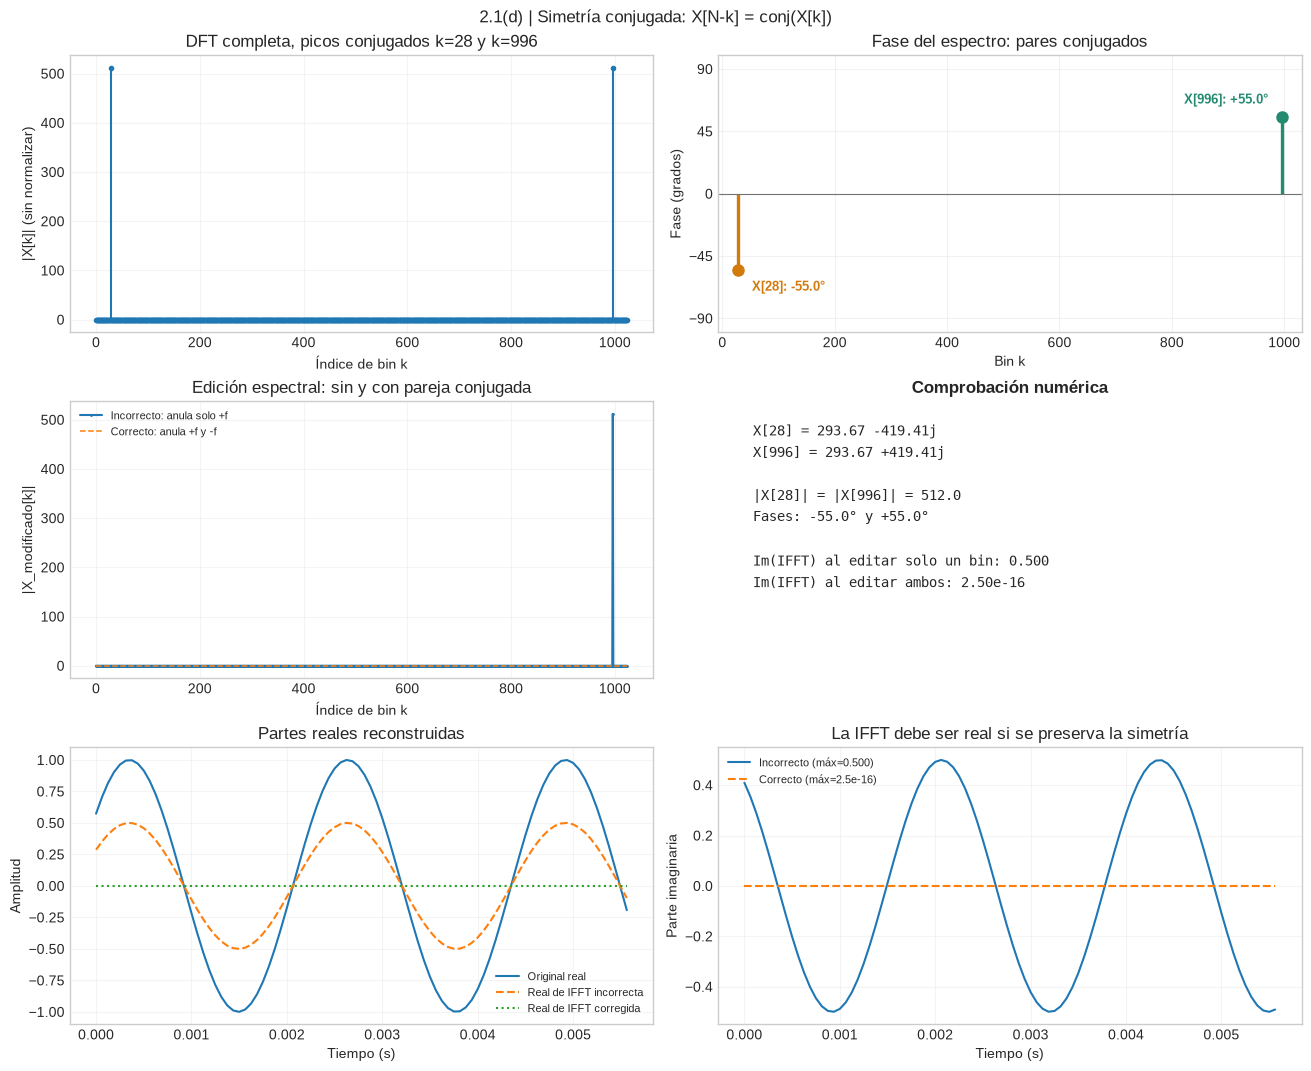

,error_absoluto,error_relativo
bin_rectangular,8.526513e-14,1.665335e-16
bin_hann,2.540804e-14,9.925014e-17
entre_rectangular,5.684342e-14,1.736157e-16
entre_hann,2.009718e-14,9.248602e-17


k_positivo                           2.800000e+01
k_negativo                           9.960000e+02
magnitud_bin_positivo                5.120000e+02
magnitud_bin_negativo                5.120000e+02
fase_bin_positivo_grados            -5.500000e+01
fase_bin_negativo_grados             5.500000e+01
error_simetria_original              8.526513e-14
error_simetria_edicion_incorrecta    5.120000e+02
error_simetria_edicion_correcta      8.526513e-14
max_imaginaria_edicion_incorrecta    4.999981e-01
max_imaginaria_edicion_correcta      2.504917e-16
dtype: float64

In [5]:
fig, SIMETRIA = ff.simetria_y_ifft(CASOS_FFT, CFG_FFT)
fig.savefig(FIGS / '2_1_simetria_conjugada.png', dpi=150, bbox_inches='tight'); plt.show()
display(pd.DataFrame(SIMETRIA.pop('errores_4_casos')).T)
pd.Series(SIMETRIA)

## 2. Configuración de los tres casos (tarea 2.2)
Parámetros comunes: fs = 16 kHz, 6 s (N = 96 000 muestras), multitono 440/880/1320 Hz. SNR objetivo = 5 dB en los tres casos: la interferencia queda ~3.6 dB por debajo del tono más fuerte, lo bastante exigente sin que la señal útil quede enterrada.

| Caso | Ruido | Relación con la banda útil |
|---|---|---|
| 1 | Interferencia sinusoidal a 1750 Hz | Separada de 440, 880 y 1320 Hz |
| 2 | Ruido blanco | Ocupa todo el espectro, pero la energía por bin es baja |
| 3 | Ruido de banda limitada 700-1500 Hz | Se superpone a los tonos de 880 y 1320 Hz |

In [6]:
BASE = dict(
    fs_Hz=16_000, duracion_s=6.0, pico_maximo=0.80, fade_ms=20,
    tipo_senal='multitono',
    frecuencias_utiles_Hz=[440, 880, 1320],
    amplitudes_utiles=[1.0, 0.55, 0.30],
    fases_grados=[0, 35, -50],
    snr_objetivo_dB=5.0,
    numero_impulsos=10,
    frecuencia_interferencia_Hz=1750,
    banda_ruido_Hz=[2500, 3800],
)

CASOS = {
    'caso_1': dict(BASE, nombre='caso_1_interferencia_sinusoidal', semilla=20261001,
                   tipo_ruido='tonal', frecuencia_interferencia_Hz=1750),
    'caso_2': dict(BASE, nombre='caso_2_ruido_blanco', semilla=20261002,
                   tipo_ruido='blanco'),
    'caso_3': dict(BASE, nombre='caso_3_banda_superpuesta', semilla=20261003,
                   tipo_ruido='banda', banda_ruido_Hz=[700, 1500]),
}
pd.DataFrame(CASOS).T[['semilla','tipo_ruido','snr_objetivo_dB','frecuencia_interferencia_Hz','banda_ruido_Hz']]

,semilla,tipo_ruido,snr_objetivo_dB,frecuencia_interferencia_Hz,banda_ruido_Hz
caso_1,20261001,tonal,5.0,1750,"[2500, 3800]"
caso_2,20261002,blanco,5.0,1750,"[2500, 3800]"
caso_3,20261003,banda,5.0,1750,"[700, 1500]"


## 3. Generación y verificación de la SNR

In [7]:
RES = {k: gs.generar_caso(cfg) for k, cfg in CASOS.items()}

filas = []
for k, cfg in CASOS.items():
    r = RES[k]
    err = r['snr_obtenida_dB'] - cfg['snr_objetivo_dB']
    assert abs(err) < 1e-3, f'{k}: SNR fuera de tolerancia ({err:.2e} dB)'
    filas.append({
        'caso': k, 'fs_Hz': cfg['fs_Hz'], 'N': len(r['t']), 'duracion_s': cfg['duracion_s'],
        'frecuencias_utiles_Hz': cfg['frecuencias_utiles_Hz'], 'tipo_ruido': cfg['tipo_ruido'],
        'semilla': cfg['semilla'], 'SNR_objetivo_dB': cfg['snr_objetivo_dB'],
        'SNR_obtenida_dB': round(r['snr_obtenida_dB'], 6), 'error_dB': f'{err:.2e}',
    })
TABLA_PARAMS = pd.DataFrame(filas).set_index('caso')
TABLA_PARAMS

,fs_Hz,N,duracion_s,frecuencias_utiles_Hz,tipo_ruido,semilla,SNR_objetivo_dB,SNR_obtenida_dB,error_dB
caso,,,,,,,,,
caso_1,16000,96000,6.0,"[440, 880, 1320]",tonal,20261001,5.0,5.0,1.33e-14
caso_2,16000,96000,6.0,"[440, 880, 1320]",blanco,20261002,5.0,5.0,7.99e-15
caso_3,16000,96000,6.0,"[440, 880, 1320]",banda,20261003,5.0,5.0,2.84e-14


La SNR obtenida coincide con la objetivo (el `assert` exige error < 0.001 dB); la diferencia residual es de redondeo en coma flotante. La normalización a pico 0.8 usa una ganancia común para señal, ruido y mezcla, por lo que no altera la SNR.

## 4. Señal temporal

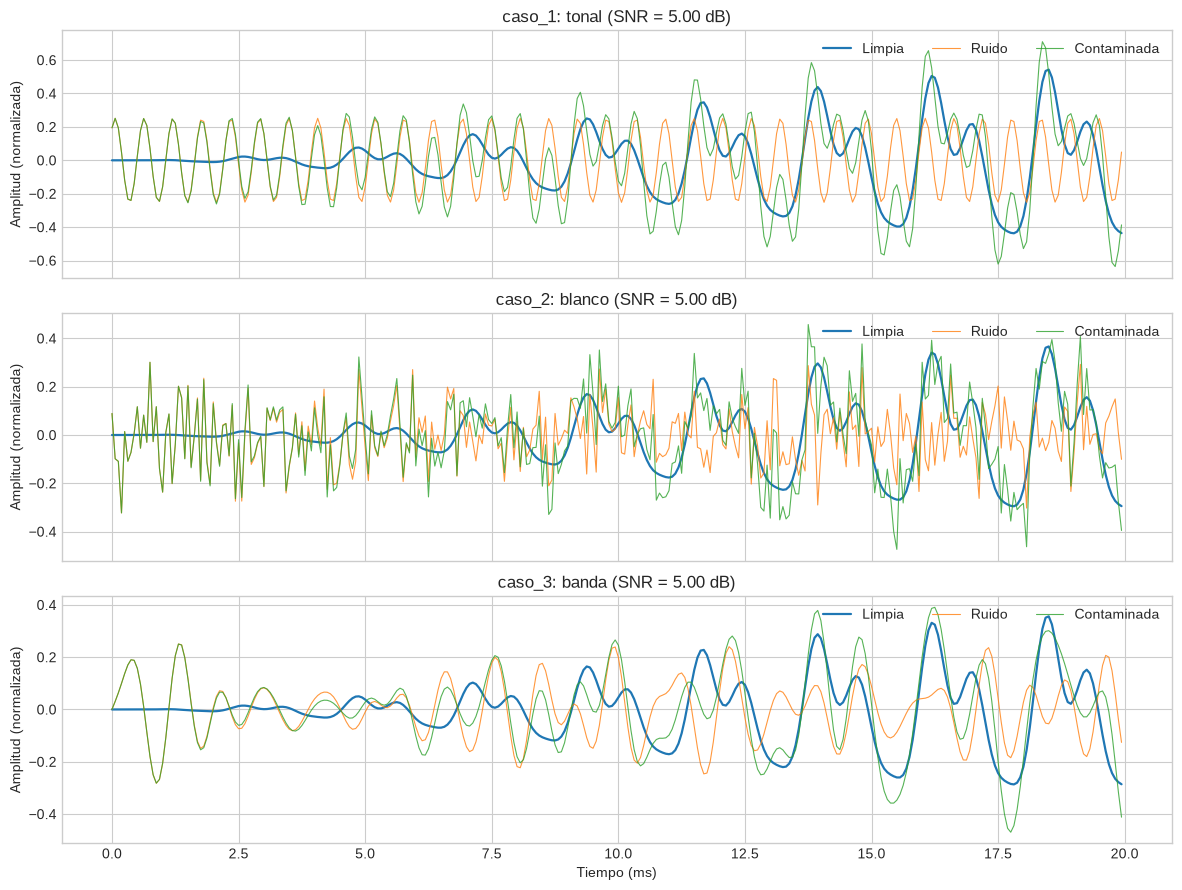

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    r = RES[k]; fs = cfg['fs_Hz']; v = int(0.02*fs)
    ax.plot(r['t'][:v]*1e3, r['clean'][:v], label='Limpia', lw=1.6)
    ax.plot(r['t'][:v]*1e3, r['noise'][:v], label='Ruido', lw=0.8, alpha=.8)
    ax.plot(r['t'][:v]*1e3, r['noisy'][:v], label='Contaminada', lw=0.8, alpha=.8)
    ax.set(ylabel='Amplitud (normalizada)', title=f"{k}: {cfg['tipo_ruido']} (SNR = {r['snr_obtenida_dB']:.2f} dB)")
    ax.legend(loc='upper right', ncol=3)
axs[-1].set_xlabel('Tiempo (ms)')
plt.tight_layout(); plt.savefig(FIGS/'2_2_senal_temporal.png', dpi=150); plt.show()

## 5. Magnitud y fase del espectro

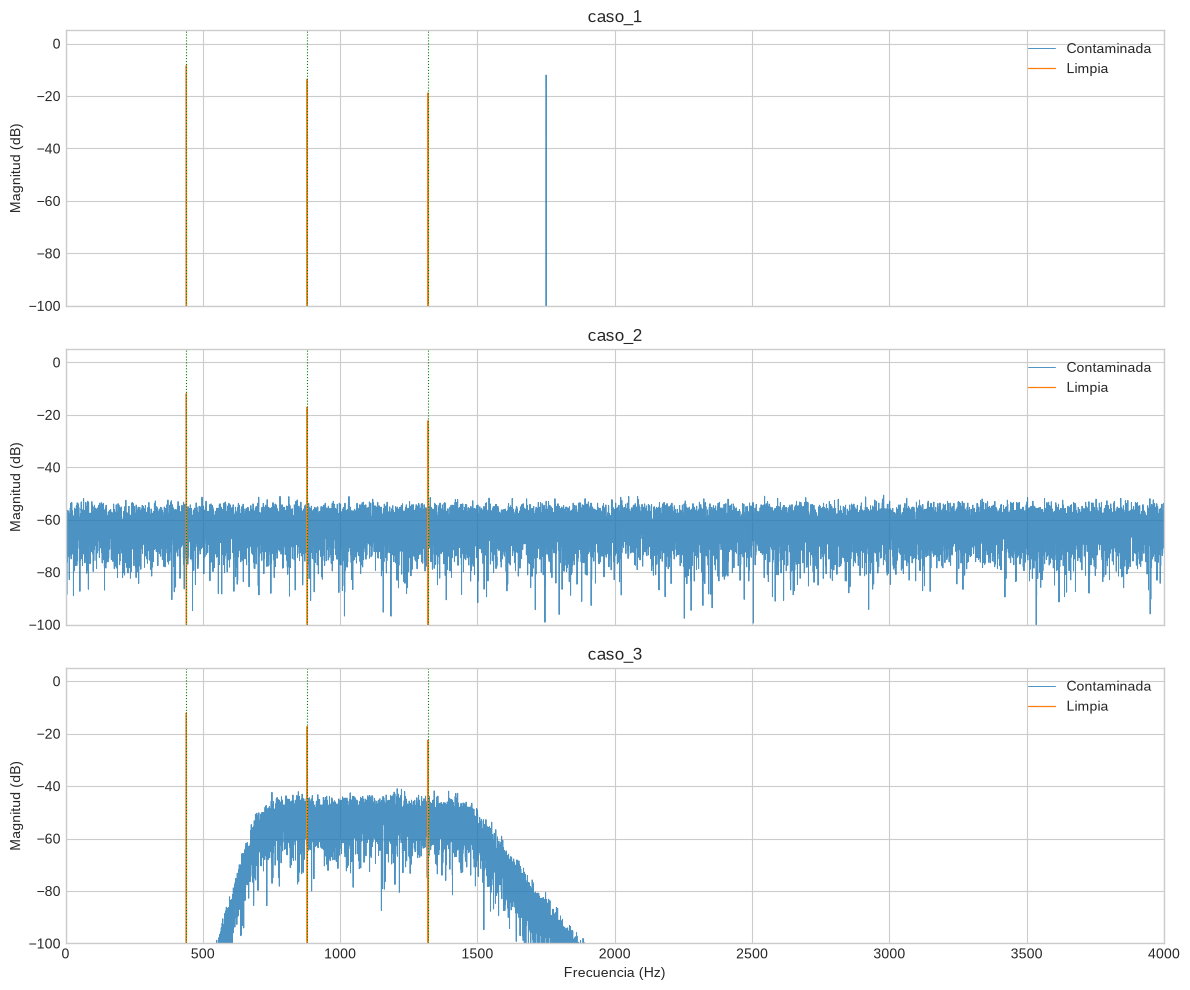

In [9]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    r = RES[k]; fs = cfg['fs_Hz']
    f, mc = gs.espectro(r['clean'], fs); _, mn = gs.espectro(r['noisy'], fs)
    ax.plot(f, mn, lw=.7, label='Contaminada', alpha=.8)
    ax.plot(f, mc, lw=.9, label='Limpia')
    for fu in cfg['frecuencias_utiles_Hz']: ax.axvline(fu, color='g', ls=':', lw=.8)
    ax.set(ylabel='Magnitud (dB)', ylim=(-100, 5), title=k); ax.legend(loc='upper right')
axs[-1].set_xlabel('Frecuencia (Hz)'); axs[-1].set_xlim(0, 4000)
plt.tight_layout(); plt.savefig(FIGS/'2_2_magnitud.png', dpi=150); plt.show()

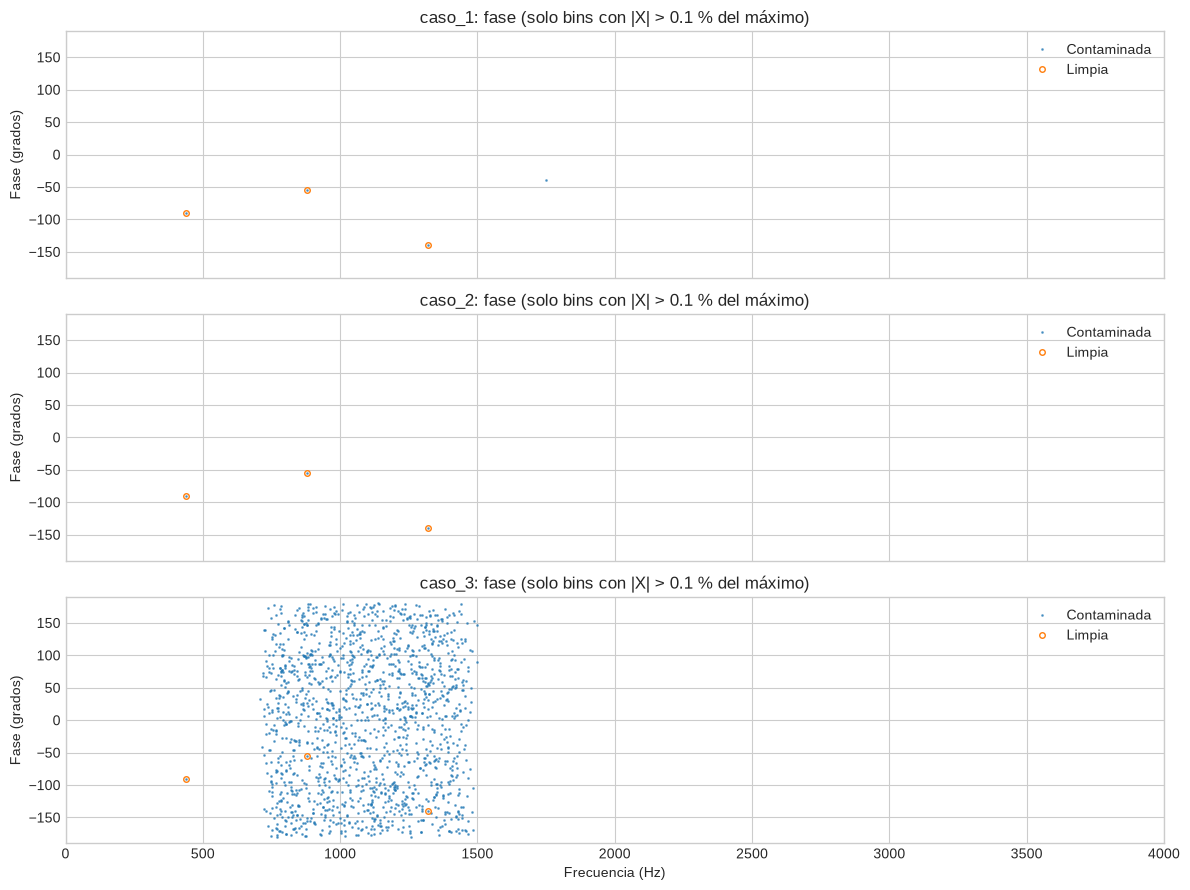

In [10]:
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    r = RES[k]; fs = cfg['fs_Hz']
    f, pc = gs.fase_espectro(r['clean'], fs); _, pn = gs.fase_espectro(r['noisy'], fs)
    ax.plot(f, pn, '.', ms=2, label='Contaminada', alpha=.6)
    ax.plot(f, pc, 'o', ms=4, mfc='none', label='Limpia')
    ax.set(ylabel='Fase (grados)', ylim=(-190, 190), title=f'{k}: fase (solo bins con |X| > 0.1 % del máximo)')
    ax.legend(loc='upper right')
axs[-1].set_xlabel('Frecuencia (Hz)'); axs[-1].set_xlim(0, 4000)
plt.tight_layout(); plt.savefig(FIGS/'2_2_fase.png', dpi=150); plt.show()

## 6. Distribución de energía por bandas

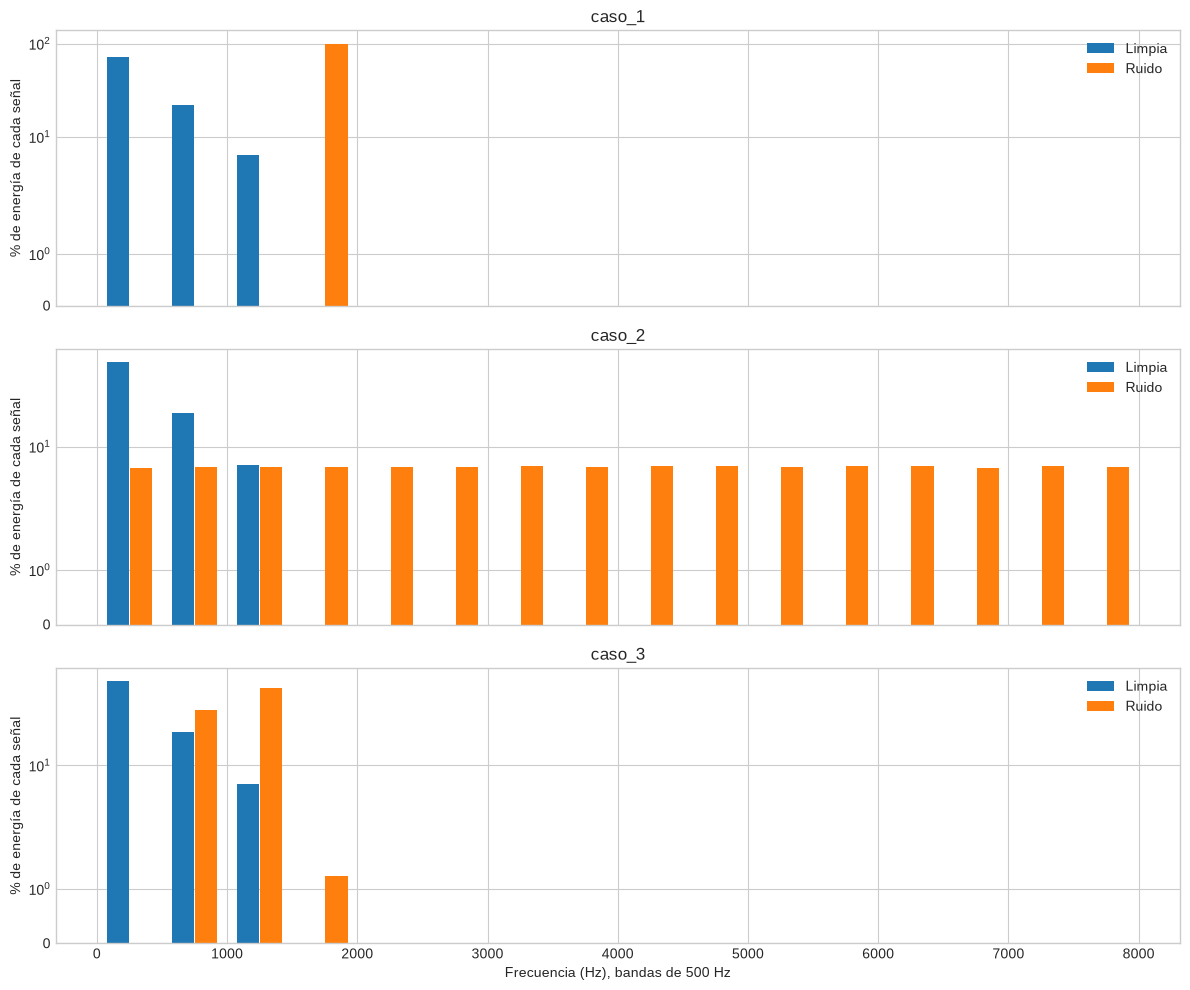

In [11]:
BORDES = np.arange(0, 8001, 500)  # 16 bandas de 500 Hz hasta Nyquist
centros = (BORDES[:-1] + BORDES[1:]) / 2

fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    r = RES[k]; fs = cfg['fs_Hz']
    ec = gs.energia_por_bandas(r['clean'], fs, BORDES) * 100
    en = gs.energia_por_bandas(r['noise'], fs, BORDES) * 100
    ax.bar(centros-90, ec, width=170, label='Limpia')
    ax.bar(centros+90, en, width=170, label='Ruido')
    ax.set(ylabel='% de energía de cada señal', yscale='symlog', title=k); ax.legend(loc='upper right')
axs[-1].set_xlabel('Frecuencia (Hz), bandas de 500 Hz')
plt.tight_layout(); plt.savefig(FIGS/'2_2_energia_bandas.png', dpi=150); plt.show()

## 7. Características para detectar automáticamente el ruido

In [12]:
filas = []
for k, cfg in CASOS.items():
    r = RES[k]
    for fuente, x in [('ruido_aislado', r['noise']), ('contaminada', r['noisy'])]:
        d = gs.caracteristicas_ruido(x, cfg['fs_Hz'])
        filas.append(dict(caso=k, tipo_ruido=cfg['tipo_ruido'], fuente=fuente, **d))
FEATURES = pd.DataFrame(filas).set_index(['caso', 'fuente']).round(3)
FEATURES

tipo_ruido  curtosis_exceso  planicidad_espectral  \
caso   fuente                                                            
caso_1 ruido_aislado      tonal           -1.500                 0.000   
       contaminada        tonal           -0.768                 0.000   
caso_2 ruido_aislado     blanco            0.010                 0.988   
       contaminada       blanco           -0.694                 0.243   
caso_3 ruido_aislado      banda           -0.010                 0.000   
       contaminada        banda           -0.678                 0.000   

                      pico_sobre_mediana_dB  ancho_banda_95_Hz  
caso   fuente                                                   
caso_1 ruido_aislado                120.000              7.812  
       contaminada                  120.000           1316.406  
caso_2 ruido_aislado                  1.918           7589.844  
       contaminada                   34.271           6734.375  
caso_3 ruido_aislado                120.000            738.281  
       contaminada                  120.000            957.031

## 8. Exportación (WAV y metadatos)


In [13]:
for k, cfg in CASOS.items():
    gs.exportar_caso(cfg, RES[k], RAIZ / 'pruebas' / k)

(RAIZ / 'metadatos').mkdir(exist_ok=True)
configuraciones = {k: dict(cfg, N=len(RES[k]['t']), snr_obtenida_dB=RES[k]['snr_obtenida_dB'],
                           ganancia_comun=float(RES[k]['ganancia'])) for k, cfg in CASOS.items()}
with open(RAIZ / 'metadatos' / 'configuraciones.json', 'w', encoding='utf-8') as f:
    json.dump(configuraciones, f, indent=2, ensure_ascii=False)

(RAIZ / 'resultados').mkdir(exist_ok=True)
TABLA_PARAMS.to_csv(TESTING / 'caracterizacion_senales.csv')
FEATURES.to_csv(TESTING / 'caracteristicas_ruido.csv')
print('Exportado:', *sorted(str(p.relative_to(RAIZ)) for p in (RAIZ/'pruebas').rglob('*') if p.is_file()), sep='\n  ')

Exportado:
  pruebas/caso_1/01_referencia_limpia.wav
  pruebas/caso_1/02_ruido.wav
  pruebas/caso_1/03_entrada_contaminada.wav
  pruebas/caso_1/metadatos_prueba.json
  pruebas/caso_2/01_referencia_limpia.wav
  pruebas/caso_2/02_ruido.wav
  pruebas/caso_2/03_entrada_contaminada.wav
  pruebas/caso_2/metadatos_prueba.json
  pruebas/caso_3/01_referencia_limpia.wav
  pruebas/caso_3/02_ruido.wav
  pruebas/caso_3/03_entrada_contaminada.wav
  pruebas/caso_3/metadatos_prueba.json


## 9. Filtro temporal (tarea 2.3)
Diseño optimizado para el caso 2: pasa bajas con banda de paso 0–1500 Hz, banda de rechazo desde 2000 Hz, rizado ≤ 1 dB y atenuación ≥ 40 dB. Se comparan Butterworth, Chebyshev I y elíptico en secciones de segundo orden (SOS). Las métricas se reportan sin alinear y alineadas por el retardo constante que maximiza la SNR; la salida de fase cero (`sosfiltfilt`) se incluye solo como referencia, porque no es causal.

In [14]:
import src.filtros_temporales as ft
from scipy.signal import (buttord, butter, cheb1ord, cheby1, ellipord, ellip, sosfilt, sosfiltfilt, lfilter, sos2tf, sos2zpk)

CFG_FILTRO = dict(caso_diseno='caso_2', banda='pasa_bajas', fp_Hz=1500, f_stop_Hz=2000,
                  Rp_dB=1.0, As_dB=40.0, tolerancia_validacion=1e-10)
FS = CASOS['caso_2']['fs_Hz']
fp, fst, rp, as_ = (CFG_FILTRO[k] for k in ('fp_Hz', 'f_stop_Hz', 'Rp_dB', 'As_dB'))


def energia_util(x, fs, freqs, ancho_hz=20):
    "Energía espectral (ventana Hann) en +-ancho_hz alrededor de cada tono útil."
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return sum(X[np.abs(f - fu) <= ancho_hz].sum() for fu in freqs)


def metricas_salida(clean, noisy, y, max_lag=36):
    "MSE, SNR y dSNR sin alinear (ec. 1-3) y alineados por el retardo constante óptimo."
    snr_in = gs.snr_db(clean, noisy)
    snr0 = gs.snr_db(clean, y)
    lag = max(range(max_lag + 1), key=lambda l: gs.snr_db(clean[:len(clean) - l], y[l:]))
    c, ya = clean[:len(clean) - lag], y[lag:]
    snr_al = gs.snr_db(c, ya)
    return dict(MSE=np.mean((clean - y) ** 2), SNR_entrada_dB=snr_in, SNR_salida_dB=snr0,
                dSNR_dB=snr0 - snr_in, retardo_alineacion_muestras=lag,
                MSE_alineado=np.mean((c - ya) ** 2), SNR_alineada_dB=snr_al,
                dSNR_alineada_dB=snr_al - snr_in)


# --- diseño de los tres prototipos (misma especificación)
SOS, ORD = {}, {}
n, wn = buttord(fp, fst, rp, as_, fs=FS)
SOS['Butterworth'], ORD['Butterworth'] = butter(n, wn, 'lowpass', fs=FS, output='sos'), int(n)
n, wn = cheb1ord(fp, fst, rp, as_, fs=FS)
SOS['Chebyshev I'], ORD['Chebyshev I'] = cheby1(n, rp, wn, 'lowpass', fs=FS, output='sos'), int(n)
n, wn = ellipord(fp, fst, rp, as_, fs=FS)
SOS['Elíptico'], ORD['Elíptico'] = ellip(n, rp, as_, wn, 'lowpass', fs=FS, output='sos'), int(n)


def fila_diseno(nombre, sos):
    w, mag, _, gd = ft.respuesta_en_frecuencia(sos, FS)
    z, p, k, radio, est = ft.polos_ceros(sos)
    K = sos.shape[0]
    return {'prototipo': nombre, 'orden': ORD[nombre], 'secciones': K, 'coeficientes': 5 * K,
            'estados': 2 * K, 'MAC_por_muestra': 5 * K, 'radio_polos_max': radio, 'estable': est,
            'G_440_dB': np.interp(440, w, mag), 'G_880_dB': np.interp(880, w, mag),
            'G_1320_dB': np.interp(1320, w, mag), 'G_1750_dB': np.interp(1750, w, mag),
            'retardo_440_muestras': np.interp(440, w, gd), 'retardo_1320_muestras': np.interp(1320, w, gd),
            'retardo_max_paso_muestras': gd[w <= fp].max()}


TABLA_DISENO = pd.DataFrame([fila_diseno(k, s) for k, s in SOS.items()]).set_index('prototipo').round(3)
display(TABLA_DISENO.T)

# --- resultado de cada prototipo sobre el caso 2 filtro causal + referencia de fase cero
r2 = RES['caso_2']
filas = []
for nombre, s in SOS.items():
    m = metricas_salida(r2['clean'], r2['noisy'], sosfilt(s, r2['noisy']))
    m['dSNR_fase_cero_ref_dB'] = gs.snr_db(r2['clean'], sosfiltfilt(s, r2['noisy'])) - m['SNR_entrada_dB']
    filas.append(dict(prototipo=nombre, **m))
TABLA_PROTOTIPOS_CASO2 = pd.DataFrame(filas).set_index('prototipo').round(3)
display(TABLA_PROTOTIPOS_CASO2.T)

prototipo,Butterworth,Chebyshev I,Elíptico
orden,17,8,5
secciones,9,4,3
coeficientes,45,20,15
estados,18,8,6
MAC_por_muestra,45,20,15
radio_polos_max,0.948,0.981,0.973
estable,True,True,True
G_440_dB,0.0,-0.489,-0.832
G_880_dB,-0.0,-0.041,-0.419
G_1320_dB,-0.012,-0.398,-0.998


prototipo,Butterworth,Chebyshev I,Elíptico
MSE,0.144,0.126,0.059
SNR_entrada_dB,5.000,5.000,5.000
SNR_salida_dB,-4.991,-4.426,-1.144
dSNR_dB,-9.991,-9.426,-6.144
retardo_alineacion_muestras,18.000,13.000,6.000
MSE_alineado,0.005,0.004,0.004
SNR_alineada_dB,9.560,10.142,10.335
dSNR_alineada_dB,4.560,5.142,5.335
dSNR_fase_cero_ref_dB,7.273,7.550,6.350


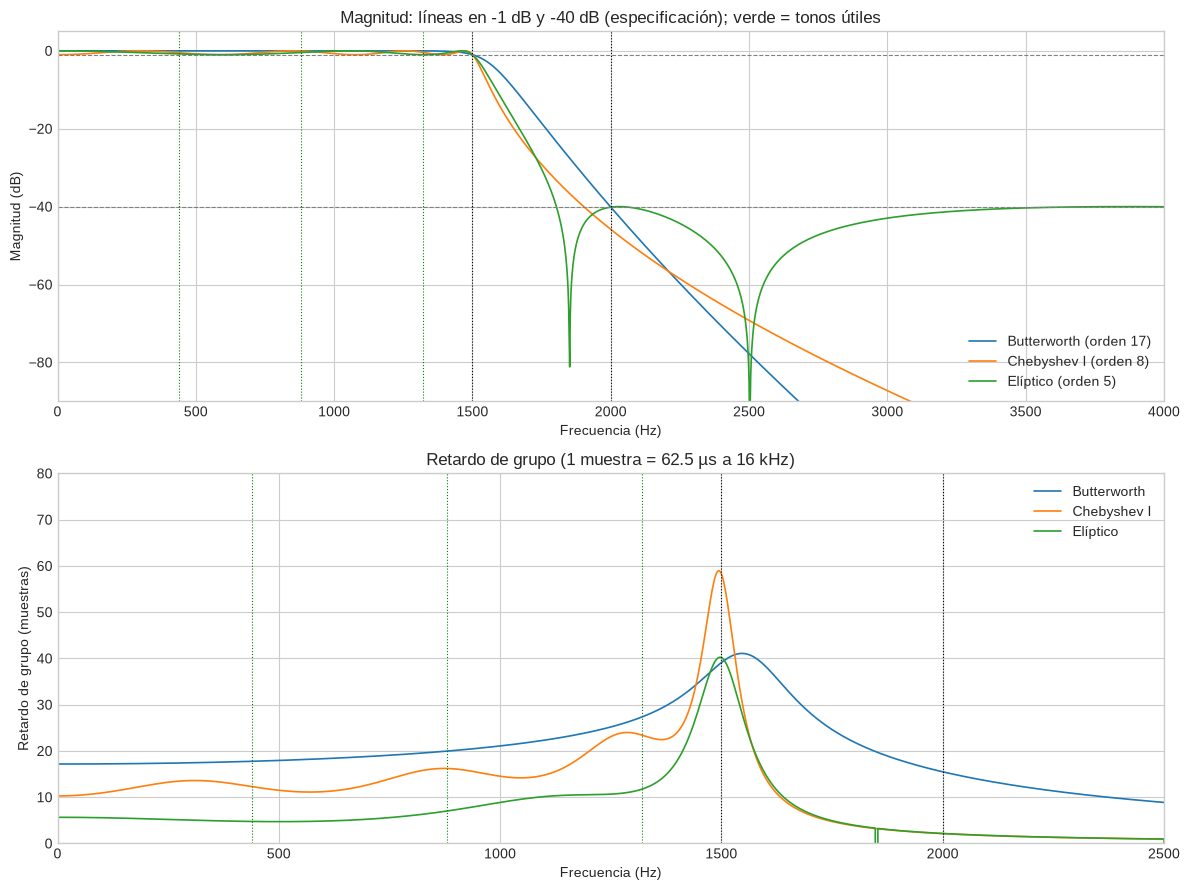

In [15]:
fig, axs = plt.subplots(2, 1, figsize=(12, 9))
for nombre, s in SOS.items():
    w, mag, fase, gd = ft.respuesta_en_frecuencia(s, FS)
    axs[0].plot(w, mag, label=f'{nombre} (orden {ORD[nombre]})', lw=1.2)
    axs[1].plot(w, gd, label=nombre, lw=1.2)
axs[0].axhline(-rp, color='gray', ls='--', lw=.8); axs[0].axhline(-as_, color='gray', ls='--', lw=.8)
for ax in axs:
    ax.axvline(fp, color='k', ls=':', lw=.8); ax.axvline(fst, color='k', ls=':', lw=.8)
    for fu in CASOS['caso_2']['frecuencias_utiles_Hz']: ax.axvline(fu, color='g', ls=':', lw=.8)
axs[0].set(xlim=(0, 4000), ylim=(-90, 5), xlabel='Frecuencia (Hz)', ylabel='Magnitud (dB)',
           title='Magnitud: líneas en -1 dB y -40 dB (especificación); verde = tonos útiles')
axs[1].set(xlim=(0, 2500), ylim=(0, 80), xlabel='Frecuencia (Hz)', ylabel='Retardo de grupo (muestras)',
           title='Retardo de grupo (1 muestra = 62.5 µs a 16 kHz)')
axs[0].legend(); axs[1].legend()
plt.tight_layout(); plt.savefig(FIGS / '2_3_comparacion_prototipos.png', dpi=150); plt.show()

### Coeficientes, H(z), polos y ceros del filtro elegido
Filtro elegido: elíptico de orden 5. La justificación está en el informe, sección 2.3.

Filtro elegido: Elíptico, orden 5, 3 secciones SOS


,b0,b1,b2,a0,a1,a2
sección 1,0.014092,0.014092,0.0,1.0,-0.790682,0.000000
sección 2,1.000000,-1.109382,1.0,1.0,-1.591158,0.776188
sección 3,1.000000,-1.494496,1.0,1.0,-1.618392,0.946023



H(z) = ganancia · Π H_i(z), con H_i(z) = (b0 + b1 z^-1 + b2 z^-2) / (1 + a1 z^-1 + a2 z^-2)
ganancia (producto de ceros/polos, de sos2zpk) k = 0.014092469

H(z) en una sola fracción, B(z)/A(z) (orden 5):
  b = [ 0.01409247 -0.02260259  0.01485471  0.01485471 -0.02260259  0.01409247]
  a = [ 1.         -4.00023237  6.835063   -6.15927027  2.91772027 -0.58059144]

Ecuación de diferencias:
  y[n] = +0.0140925·x[n-0] -0.0226026·x[n-1] +0.0148547·x[n-2] +0.0148547·x[n-3] -0.0226026·x[n-4] +0.0140925·x[n-5] +4.00023·y[n-1] -6.83506·y[n-2] +6.15927·y[n-3] -2.91772·y[n-4] +0.580591·y[n-5]

Radio máximo de los polos = 0.97264  ->  ROC causal: |z| > 0.97264  ->  estable (la ROC contiene la circunferencia unitaria)


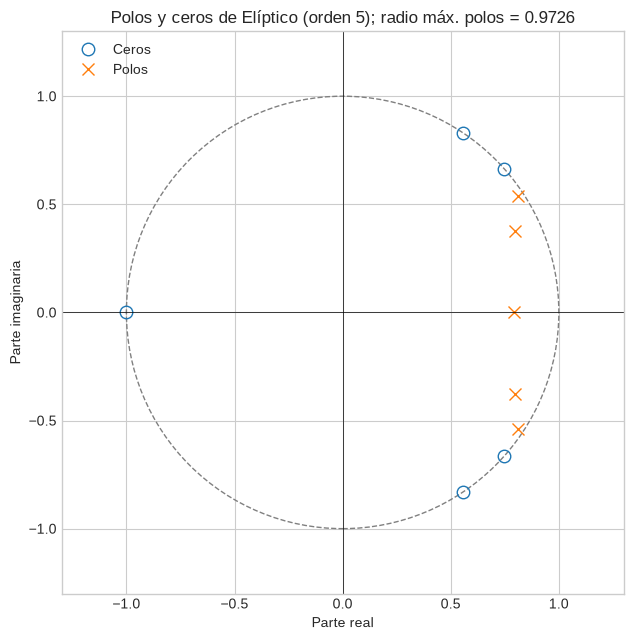

In [16]:
ELEGIDO = 'Elíptico'
sos = SOS[ELEGIDO]
b, a = sos2tf(sos)
z, p, k = sos2zpk(sos)

print(f'Filtro elegido: {ELEGIDO}, orden {ORD[ELEGIDO]}, {sos.shape[0]} secciones SOS')
display(pd.DataFrame(sos, columns=['b0', 'b1', 'b2', 'a0', 'a1', 'a2'],
                     index=[f'sección {i + 1}' for i in range(sos.shape[0])]).round(8))

print('\nH(z) = ganancia · Π H_i(z), con H_i(z) = (b0 + b1 z^-1 + b2 z^-2) / (1 + a1 z^-1 + a2 z^-2)')
print(f'ganancia (producto de ceros/polos, de sos2zpk) k = {k:.8g}')
b_t, a_t = np.trim_zeros(b, 'b'), np.trim_zeros(a, 'b')   
print('\nH(z) en una sola fracción, B(z)/A(z) (orden 5):')
print('  b =', np.array2string(b_t, precision=8, max_line_width=110))
print('  a =', np.array2string(a_t, precision=8, max_line_width=110))
ent = ' '.join(f'{c:+.6g}·x[n-{i}]' for i, c in enumerate(b_t))
sal = ' '.join(f'{-c:+.6g}·y[n-{i}]' for i, c in enumerate(a_t) if i > 0)
print('\nEcuación de diferencias:\n  y[n] =', ent, sal)

_, _, _, radio, estable = ft.polos_ceros(sos)
print(f'\nRadio máximo de los polos = {radio:.5f}  ->  ROC causal: |z| > {radio:.5f}  ->  '
      f'{"estable (la ROC contiene la circunferencia unitaria)" if estable else "INESTABLE"}')

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='gray', ls='--'))
zp, pp = z[np.abs(z) > 1e-9], p[np.abs(p) > 1e-9]   
ax.plot(zp.real, zp.imag, 'o', mfc='none', ms=9, label='Ceros')
ax.plot(pp.real, pp.imag, 'x', ms=9, label='Polos')
ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect='equal', xlabel='Parte real', ylabel='Parte imaginaria',
       title=f'Polos y ceros de {ELEGIDO} (orden {ORD[ELEGIDO]}); radio máx. polos = {radio:.4f}')
ax.legend(loc='upper left')
plt.tight_layout(); plt.savefig(FIGS / '2_3_polos_ceros.png', dpi=150); plt.show()

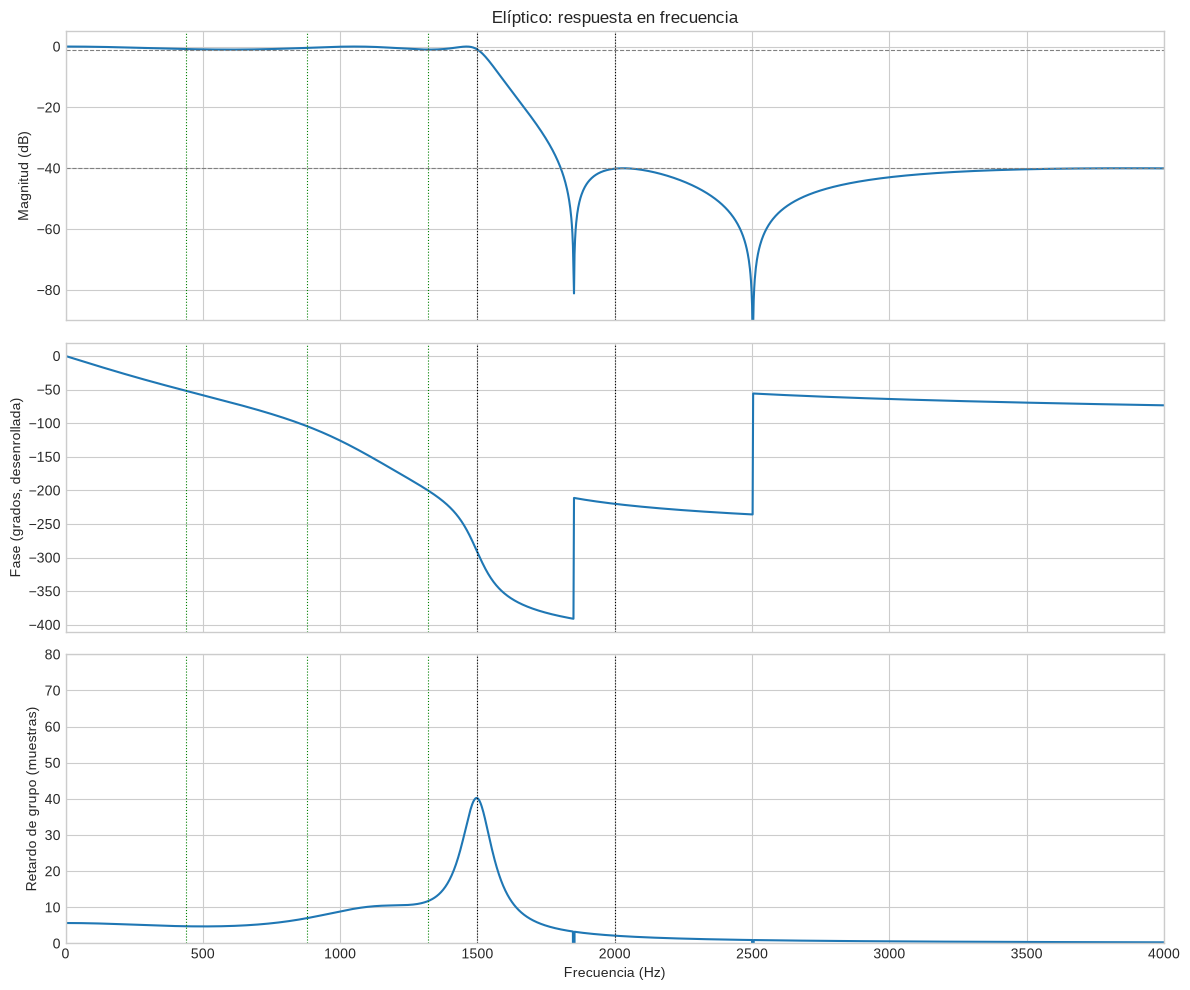

In [17]:
w, mag, fase, gd = ft.respuesta_en_frecuencia(sos, FS)
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axs[0].plot(w, mag); axs[0].set(ylabel='Magnitud (dB)', ylim=(-90, 5), title=f'{ELEGIDO}: respuesta en frecuencia')
axs[1].plot(w, np.degrees(fase)); axs[1].set(ylabel='Fase (grados, desenrollada)')
axs[2].plot(w, gd); axs[2].set(ylabel='Retardo de grupo (muestras)', xlabel='Frecuencia (Hz)', ylim=(0, 80))
for ax in axs:
    ax.axvline(fp, color='k', ls=':', lw=.8); ax.axvline(fst, color='k', ls=':', lw=.8)
    for fu in CASOS['caso_2']['frecuencias_utiles_Hz']: ax.axvline(fu, color='g', ls=':', lw=.8)
axs[0].axhline(-rp, color='gray', ls='--', lw=.8); axs[0].axhline(-as_, color='gray', ls='--', lw=.8)
axs[-1].set_xlim(0, 4000)
plt.tight_layout(); plt.savefig(FIGS / '2_3_respuesta_elegido.png', dpi=150); plt.show()

### Validación de la ecuación de diferencias
Compara `aplicar_sos_manual` (ecuación de diferencias implementada a mano) con `sosfilt` y con `lfilter(b, a)`. El `assert` falla si el error supera la tolerancia declarada de 1e-10.

In [18]:
TOL = CFG_FILTRO['tolerancia_validacion']
VALIDACION = []
for nombre, x in [('ruido gaussiano (semilla 0)', np.random.default_rng(0).standard_normal(96_000)),
                  ('caso 2 contaminada', RES['caso_2']['noisy'])]:
    y_man = ft.aplicar_sos_manual(sos, x)
    e_sos = np.max(np.abs(y_man - sosfilt(sos, x)))
    e_ba = np.max(np.abs(y_man - lfilter(b, a, x)))
    assert e_sos < TOL, f'{nombre}: manual vs sosfilt = {e_sos:.2e} (tolerancia {TOL:.0e})'
    VALIDACION.append({'entrada': nombre, 'error_max_vs_sosfilt': e_sos, 'error_max_vs_lfilter(b,a)': e_ba})
display(pd.DataFrame(VALIDACION).set_index('entrada'))

,error_max_vs_sosfilt,"error_max_vs_lfilter(b,a)"
entrada,,
ruido gaussiano (semilla 0),0.0,2.469691e-13
caso 2 contaminada,0.0,7.775031e-14


### Aplicación del filtro a los tres casos

caso,caso_1,caso_2,caso_3
metodo,temporal_Elíptico,temporal_Elíptico,temporal_Elíptico
N_bloque,NaN,NaN,NaN
alpha,NaN,NaN,NaN
MSE,0.1249,0.0594,0.066
SNR_entrada_dB,5.0,5.0,5.0
SNR_salida_dB,-0.9684,-1.1438,-1.8539
dSNR_dB,-5.9684,-6.1438,-6.8539
retardo_alineacion_muestras,6,6,6
MSE_alineado,0.004,0.0042,0.0139
SNR_alineada_dB,14.0233,10.335,4.923


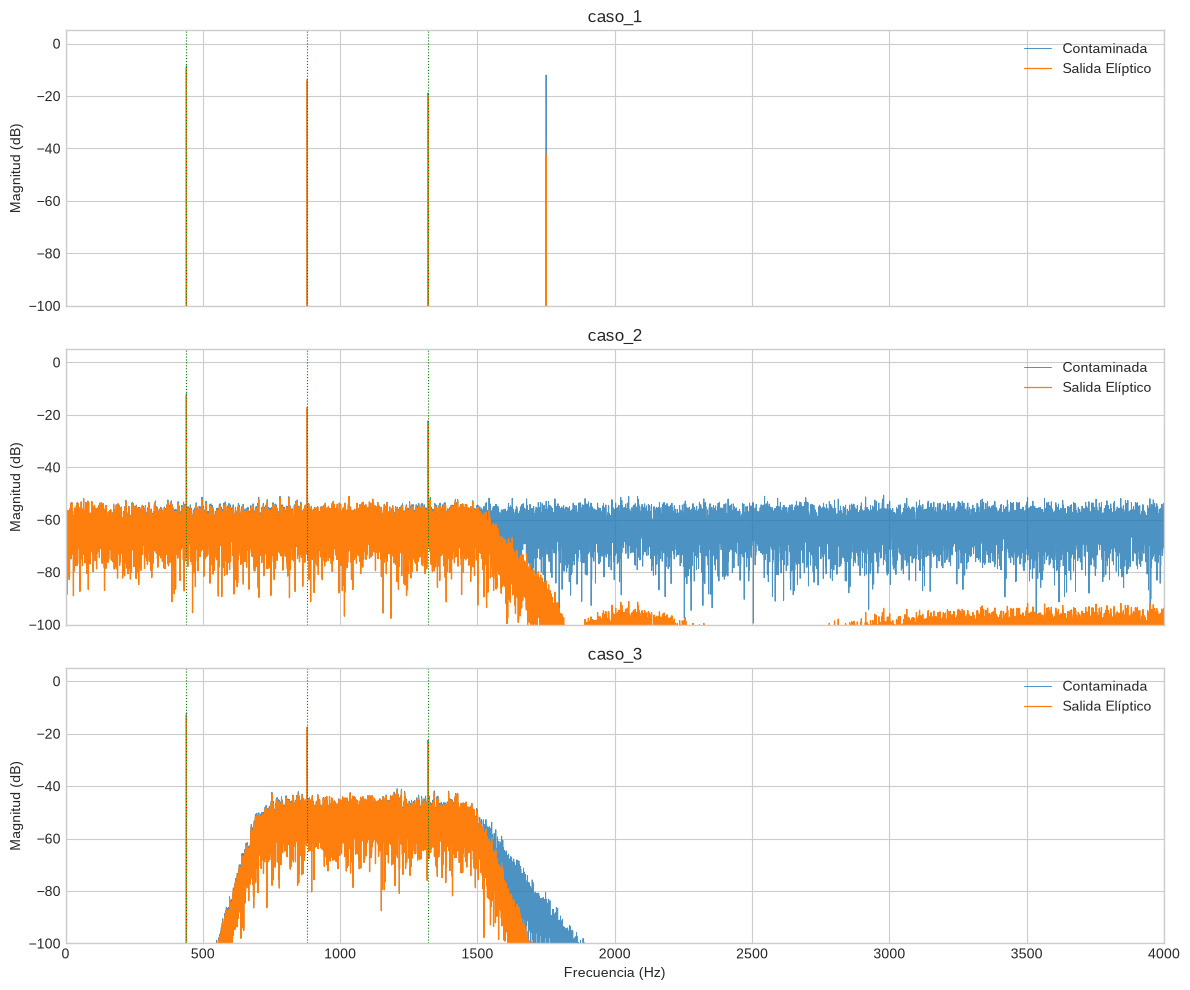

In [19]:
SAL_TEMP = {k: ft.aplicar_sos_manual(sos, RES[k]['noisy']) for k in CASOS}

filas = []
for k, cfg in CASOS.items():
    r, fs, y = RES[k], cfg['fs_Hz'], SAL_TEMP[k]
    util = cfg['frecuencias_utiles_Hz']
    att = (10 * np.log10(energia_util(r['noisy'], fs, [1750]) / energia_util(y, fs, [1750]))
           if k == 'caso_1' else np.nan)
    filas.append({'caso': k, 'metodo': f'temporal_{ELEGIDO}', 'N_bloque': np.nan, 'alpha': np.nan,
                  **metricas_salida(r['clean'], r['noisy'], y),
                  'energia_util_conservada_%': 100 * energia_util(y, fs, util) / energia_util(r['clean'], fs, util),
                  'atenuacion_interferencia_dB': att})
METRICAS_TEMP = pd.DataFrame(filas).set_index('caso').round(4)
display(METRICAS_TEMP.T)

fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    f, m_in = gs.espectro(RES[k]['noisy'], cfg['fs_Hz']); _, m_out = gs.espectro(SAL_TEMP[k], cfg['fs_Hz'])
    ax.plot(f, m_in, lw=.7, alpha=.8, label='Contaminada'); ax.plot(f, m_out, lw=.9, label=f'Salida {ELEGIDO}')
    for fu in cfg['frecuencias_utiles_Hz']: ax.axvline(fu, color='g', ls=':', lw=.8)
    ax.set(ylabel='Magnitud (dB)', ylim=(-100, 5), title=k); ax.legend(loc='upper right')
axs[-1].set_xlabel('Frecuencia (Hz)'); axs[-1].set_xlim(0, 4000)
plt.tight_layout(); plt.savefig(FIGS / '2_3_aplicacion_tres_casos.png', dpi=150); plt.show()

### Cuantización de coeficientes y memoria
Redondea los coeficientes a b bits fraccionarios (rango [−2, 2)) y recalcula la respuesta, el radio de los polos y la estabilidad.

In [20]:
def cuantizar_sos(sos, bits_fraccion):
    paso = 2.0 ** -bits_fraccion
    return np.clip(np.round(sos / paso) * paso, -2.0, 2.0 - paso)     # formato con rango [-2, 2)


filas = []
for bits in (15, 14, 12, 10, 8):
    sq = cuantizar_sos(sos, bits)
    w, mag, _, _ = ft.respuesta_en_frecuencia(sq, FS)
    _, _, _, radio_q, est_q = ft.polos_ceros(sq)
    filas.append({'bits_fraccion': bits, 'estable': est_q, 'radio_polos_max': radio_q,
                  'desv_max_banda_paso_dB': np.max(np.abs(mag[w <= fp])),
                  'atenuacion_min_rechazo_dB': -np.max(mag[w >= fst])})
display(pd.DataFrame(filas).set_index('bits_fraccion').round(3))
K = sos.shape[0]
print(f'Memoria en float32: {5 * K} coef. + {2 * K} estados = {7 * K * 4} bytes; en 16 bits: {7 * K * 2} bytes')

,estable,radio_polos_max,desv_max_banda_paso_dB,atenuacion_min_rechazo_dB
bits_fraccion,,,,
15,True,0.973,0.998,39.995
14,True,0.973,0.997,39.996
12,True,0.973,0.957,39.959
10,True,0.973,1.293,40.263
8,True,0.972,0.776,38.885


Memoria en float32: 15 coef. + 6 estados = 84 bytes; en 16 bits: 42 bytes


## 10. Reducción espectral mediante FFT/IFFT (tarea 2.4)
Cadena (`src/filtrado_espectral.py`): bloque de N = 1024 muestras → ventana raíz de Hann → `rfft` → ganancia por bin → `irfft` → ventana de síntesis → solapamiento y suma con 50 % de solape. Ganancia: $G[k]^2 = \max\left(1 - \alpha P_n[k]/P[k],\; g_{min}^2\right)$, con α = 2 y $g_{min}$ = 0.1. Parámetros adaptativos, estimados con los primeros 2 s: piso de ruido por bin y frecuencias interferentes.

In [21]:
import src.filtrado_espectral as fe

N_BLOQUE, ALPHA, G_MIN = 1024, 2.0, 0.1


def procesar(r, cfg, alpha=ALPHA, g_min=G_MIN):
    fs = cfg['fs_Hz']
    pn, fint, info = fe.estimar_ruido_e_interferencia(r['noisy'][:2 * fs], fs, N_BLOQUE)
    y, G = fe.reducir_ruido_fft(r['noisy'], fs, pn, fint, N_BLOQUE, alpha=alpha, g_min=g_min)
    return y, fint, info


filas, SAL_ESP, PN = [], {}, {}
for k, cfg in CASOS.items():
    r, fs = RES[k], cfg['fs_Hz']
    y, fint, info = procesar(r, cfg)
    SAL_ESP[k] = y
    PN[k] = fe.estimar_ruido_e_interferencia(r['noisy'][:2 * fs], fs, N_BLOQUE)[0]
    util = cfg['frecuencias_utiles_Hz']
    att = (10 * np.log10(energia_util(r['noisy'], fs, [1750]) / energia_util(y, fs, [1750]))
           if k == 'caso_1' else np.nan)
    filas.append({'caso': k, 'metodo': 'espectral', 'N_bloque': N_BLOQUE, 'alpha': ALPHA,
                  'interferencias_estimadas_Hz': [round(v, 1) for v in fint],
                  **metricas_salida(r['clean'], r['noisy'], y),
                  'energia_util_conservada_%': 100 * energia_util(y, fs, util) / energia_util(r['clean'], fs, util),
                  'atenuacion_interferencia_dB': att})
METRICAS_ESP = pd.DataFrame(filas).set_index('caso').round(4)
display(METRICAS_ESP.T)

caso,caso_1,caso_2,caso_3
metodo,espectral,espectral,espectral
N_bloque,1024,1024,1024
alpha,2.0,2.0,2.0
interferencias_estimadas_Hz,[1750.0],[],[]
MSE,0.0004,0.0019,0.0027
SNR_entrada_dB,5.0,5.0,5.0
SNR_salida_dB,23.8678,13.7674,11.9975
dSNR_dB,18.8678,8.7674,6.9975
retardo_alineacion_muestras,0,0,0
MSE_alineado,0.0004,0.0019,0.0027


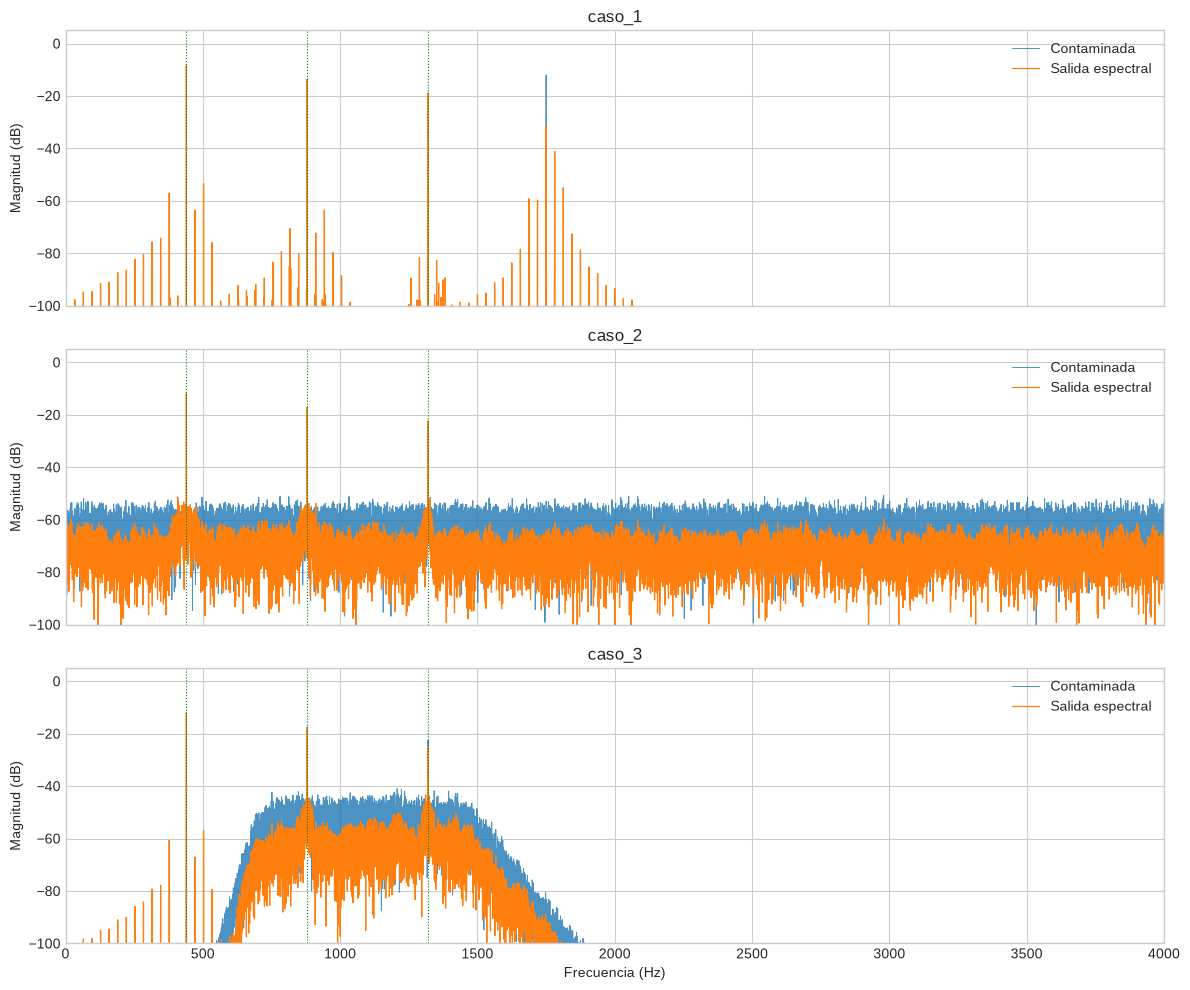

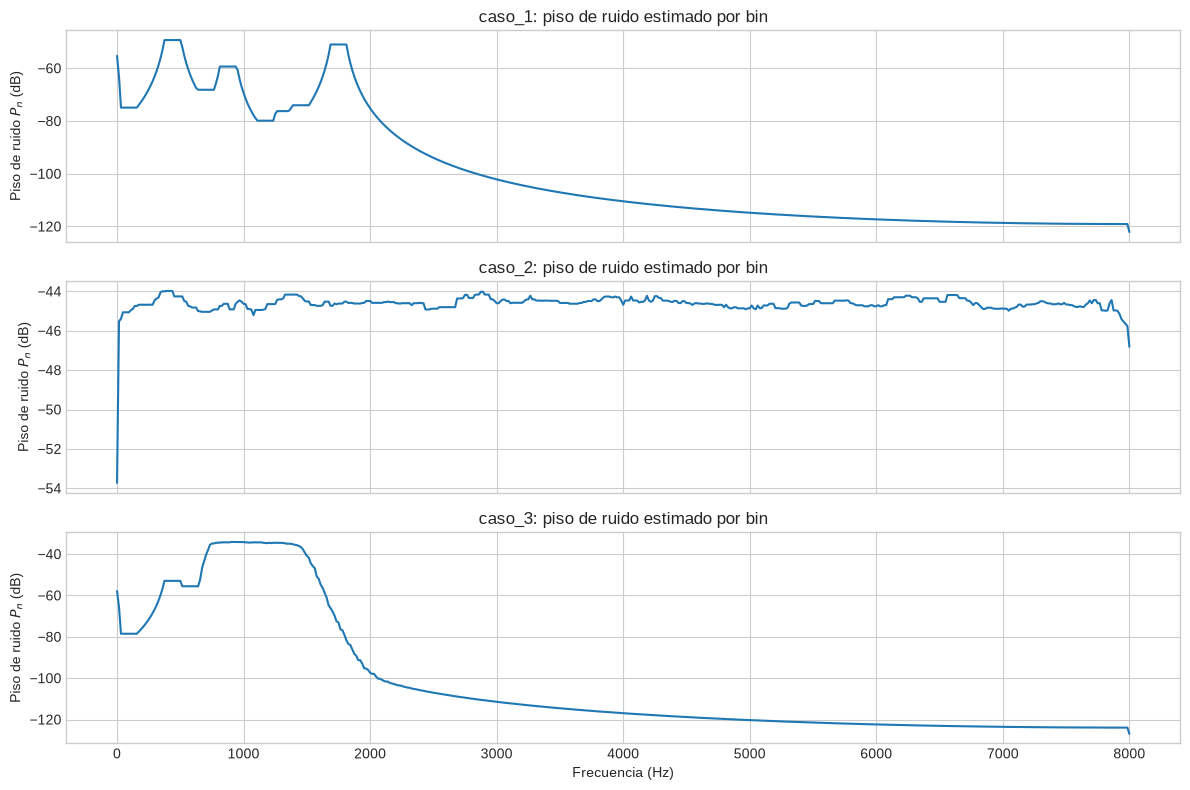

In [22]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    fs = cfg['fs_Hz']
    f, m_in = gs.espectro(RES[k]['noisy'], fs); _, m_out = gs.espectro(SAL_ESP[k], fs)
    ax.plot(f, m_in, lw=.7, alpha=.8, label='Contaminada')
    ax.plot(f, m_out, lw=.9, label='Salida espectral')
    for fu in cfg['frecuencias_utiles_Hz']: ax.axvline(fu, color='g', ls=':', lw=.8)
    ax.set(ylabel='Magnitud (dB)', ylim=(-100, 5), title=k); ax.legend(loc='upper right')
axs[-1].set_xlabel('Frecuencia (Hz)'); axs[-1].set_xlim(0, 4000)
plt.tight_layout(); plt.savefig(FIGS / '2_4_magnitud.png', dpi=150); plt.show()

# Piso de ruido estimado por bin: muestra que el método se adapta a cada tipo de ruido
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (k, cfg) in zip(axs, CASOS.items()):
    f_blk = np.fft.rfftfreq(N_BLOQUE, 1 / cfg['fs_Hz'])
    ax.plot(f_blk, 10 * np.log10(PN[k] + 1e-20))
    ax.set(ylabel='Piso de ruido $P_n$ (dB)', title=f'{k}: piso de ruido estimado por bin')
axs[-1].set_xlabel('Frecuencia (Hz)')
plt.tight_layout(); plt.savefig(FIGS / '2_4_piso_ruido.png', dpi=150); plt.show()

### Compromiso entre ruido eliminado y distorsión (caso 3)
Barrido de α: SNR de salida y energía útil conservada.

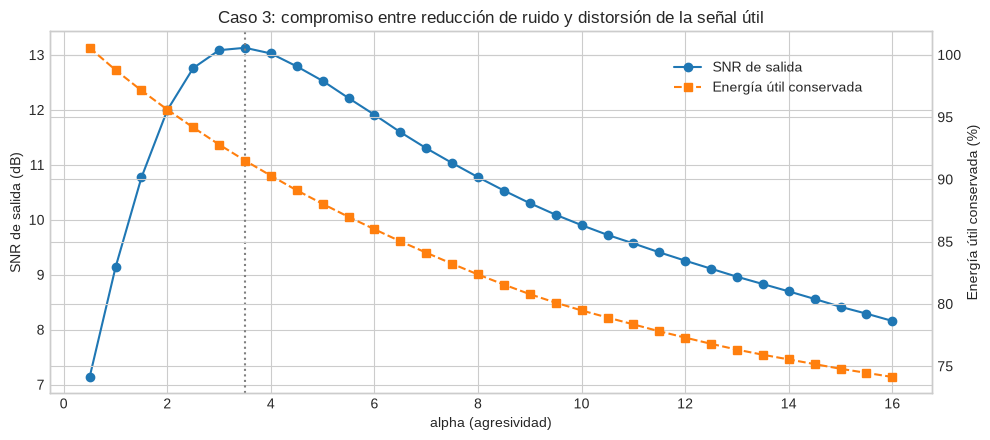

alpha óptimo: 3.5 | SNR máx: 13.13 | SNR con alpha=16: 8.16 | energía útil con alpha=16: 74.1 %


In [23]:
cfg3, r3 = CASOS['caso_3'], RES['caso_3']
alphas = np.arange(0.5, 16.5, 0.5)
barrido = []
for a_ in alphas:
    y, _, _ = procesar(r3, cfg3, alpha=a_)
    barrido.append((gs.snr_db(r3['clean'], y),
                    100 * energia_util(y, cfg3['fs_Hz'], cfg3['frecuencias_utiles_Hz'])
                    / energia_util(r3['clean'], cfg3['fs_Hz'], cfg3['frecuencias_utiles_Hz'])))
barrido = np.array(barrido)

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(alphas, barrido[:, 0], 'o-', label='SNR de salida')
ax1.set(xlabel='alpha (agresividad)', ylabel='SNR de salida (dB)')
ax2 = ax1.twinx()
ax2.plot(alphas, barrido[:, 1], 's--', color='C1', label='Energía útil conservada')
ax2.set_ylabel('Energía útil conservada (%)')
ax1.axvline(alphas[np.argmax(barrido[:, 0])], color='gray', ls=':')
ax1.set_title('Caso 3: compromiso entre reducción de ruido y distorsión de la señal útil')
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
plt.tight_layout(); plt.savefig(FIGS / '2_4_barrido_alpha.png', dpi=150); plt.show()
print('alpha óptimo:', alphas[np.argmax(barrido[:, 0])], '| SNR máx:', barrido[:, 0].max().round(2),
      '| SNR con alpha=16:', barrido[-1, 0].round(2),
      '| energía útil con alpha=16: %.1f %%' % barrido[-1, 1])

### Registro de la configuración de los filtros

In [24]:
ruta = RAIZ / 'metadatos' / 'configuraciones.json'
with open(ruta, encoding='utf-8') as f:
    cfgs = json.load(f)
cfgs['fundamentos_fft'] = CFG_FFT
cfgs['filtro_temporal'] = dict(CFG_FILTRO, prototipo=ELEGIDO, orden=ORD[ELEGIDO],
                               secciones_sos=int(sos.shape[0]), implementacion='sos_forma_directa_II_transpuesta')
cfgs['filtrado_espectral'] = dict(n_bloque=N_BLOQUE, solape=0.5, ventana='raiz_hann', alpha=ALPHA, g_min=G_MIN,
                                  calibracion_s=2, n_est=8192, kernel_piso_Hz=250, umbral_pico_dB=15,
                                  tolerancia_armonico_Hz=5, ancho_rechazo_bins=2)
with open(ruta, 'w', encoding='utf-8') as f:
    json.dump(cfgs, f, indent=2, ensure_ascii=False)
print('Escrito: metadatos/configuraciones.json')


Escrito: metadatos/configuraciones.json


## 11. Comparación y propuesta para el sistema embebido (tarea 2.5)

### 11.1 Atenuación del ruido dominante
Energía del ruido antes y después de cada método, medida en: caso 1, 1750 ± 20 Hz; caso 2, todo el espectro; caso 3, 700–1500 Hz. La señal limpia y el ruido se pasan por separado por cada sistema, que es lineal con sus parámetros fijos; la celda verifica esa linealidad con tolerancia 1e-10.

In [25]:
TOL_LIN = 1e-10
BANDA_ATENUACION = {'caso_1': (1730, 1770), 'caso_2': None, 'caso_3': (700, 1500)}   # None = espectro completo


def energia_banda(x, fs, banda=None):
    "Energía |FFT|^2 de x dentro de banda=(f_ini, f_fin) en Hz, o en todo el espectro si banda es None."
    P = np.abs(np.fft.rfft(x)) ** 2
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return P.sum() if banda is None else P[(f >= banda[0]) & (f <= banda[1])].sum()


ATEN, LINEALIDAD = {}, []
for k, cfg in CASOS.items():
    r, fs = RES[k], cfg['fs_Hz']
    # Temporal: filtro LTI aplicado por separado a limpia y ruido
    yc_t = ft.aplicar_sos_manual(sos, r['clean']); yn_t = ft.aplicar_sos_manual(sos, r['noise'])
    # Espectral: ganancias calculadas con la contaminada y aplicadas por separado
    pn, fint, _ = fe.estimar_ruido_e_interferencia(r['noisy'][:2 * fs], fs, N_BLOQUE)
    y_e, G = fe.reducir_ruido_fft(r['noisy'], fs, pn, fint, N_BLOQUE, alpha=ALPHA, g_min=G_MIN)
    yc_e = fe.aplicar_ganancias_fft(r['clean'], G, N_BLOQUE); yn_e = fe.aplicar_ganancias_fft(r['noise'], G, N_BLOQUE)

    err_t = np.max(np.abs(yc_t + yn_t - SAL_TEMP[k])); err_e = np.max(np.abs(yc_e + yn_e - SAL_ESP[k]))
    assert err_t < TOL_LIN and err_e < TOL_LIN, f'{k}: linealidad fuera de tolerancia ({err_t:.1e}, {err_e:.1e})'
    LINEALIDAD.append({'caso': k, 'error_max_temporal': err_t, 'error_max_espectral': err_e})

    e_in = energia_banda(r['noise'], fs, BANDA_ATENUACION[k])
    ATEN[k] = {'temporal': 10 * np.log10(e_in / energia_banda(yn_t, fs, BANDA_ATENUACION[k])),
               'espectral': 10 * np.log10(e_in / energia_banda(yn_e, fs, BANDA_ATENUACION[k]))}
display(pd.DataFrame(LINEALIDAD).set_index('caso'))
display(pd.DataFrame(ATEN).T.round(2).rename(columns=lambda c: f'atenuación {c} (dB)'))

,error_max_temporal,error_max_espectral
caso,,
caso_1,1.623701e-15,3.330669e-16
caso_2,1.387779e-15,4.440892e-16
caso_3,1.360023e-15,2.775558e-16


,atenuación temporal (dB),atenuación espectral (dB)
caso_1,30.36,19.61
caso_2,7.70,8.92
caso_3,0.44,8.08


Sensibilidad de la zona elegida en el caso 3, y atenuación junto a los tonos útiles (880 y 1320 Hz, ±20 Hz).

In [26]:
r3, fs3 = RES['caso_3'], CASOS['caso_3']['fs_Hz']
yn_t3 = ft.aplicar_sos_manual(sos, r3['noise'])
pn3, fint3, _ = fe.estimar_ruido_e_interferencia(r3['noisy'][:2 * fs3], fs3, N_BLOQUE)
_, G3 = fe.reducir_ruido_fft(r3['noisy'], fs3, pn3, fint3, N_BLOQUE, alpha=ALPHA, g_min=G_MIN)
yn_e3 = fe.aplicar_ganancias_fft(r3['noise'], G3, N_BLOQUE)

filas = []
for nombre, banda in [('700-1500 Hz (elegida)', (700, 1500)), ('600-1600 Hz', (600, 1600)),
                      ('500-1800 Hz', (500, 1800)), ('Espectro completo', None),
                      ('880 ± 20 Hz (tono)', (860, 900)), ('1320 ± 20 Hz (tono)', (1300, 1340))]:
    e_in = energia_banda(r3['noise'], fs3, banda)
    filas.append({'zona': nombre,
                  '% energía del ruido': 100 * e_in / energia_banda(r3['noise'], fs3),
                  'temporal (dB)': 10 * np.log10(e_in / energia_banda(yn_t3, fs3, banda)),
                  'espectral (dB)': 10 * np.log10(e_in / energia_banda(yn_e3, fs3, banda))})
SENSIBILIDAD_ZONA = pd.DataFrame(filas).set_index('zona').round(2)
SENSIBILIDAD_ZONA

,% energía del ruido,temporal (dB),espectral (dB)
zona,,,
700-1500 Hz (elegida),98.20,0.44,8.08
600-1600 Hz,99.94,0.47,8.09
500-1800 Hz,99.99,0.47,8.09
Espectro completo,100.00,0.47,8.09
880 ± 20 Hz (tono),5.58,0.42,2.26
1320 ± 20 Hz (tono),5.63,1.00,4.35


### 11.2 Tiempo de ejecución por bloque
Mediana de 15 repeticiones con `time.perf_counter()`, sobre la señal del caso 2. Temporal: `sosfilt` por bloques de 1024 muestras conservando el estado del filtro. Espectral: `reducir_ruido_fft` dividido entre el número de bloques (cada bloque avanza 512 muestras). Son tiempos de PC, no del ESP32.

In [27]:
import time


def mediana_tiempo(f, repeticiones=15):
    "Mediana en segundos de `repeticiones` ejecuciones de f()."
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter(); f(); tiempos.append(time.perf_counter() - t0)
    return float(np.median(tiempos))


x_t, fs_t = RES['caso_2']['noisy'], CASOS['caso_2']['fs_Hz']

# Temporal: bloques de N_BLOQUE muestras con el estado del filtro entre bloques
bloques = [x_t[i:i + N_BLOQUE] for i in range(0, len(x_t) - N_BLOQUE + 1, N_BLOQUE)]
def correr_temporal():
    zi = np.zeros((sos.shape[0], 2))
    for b in bloques:
        _, zi = sosfilt(sos, b, zi=zi)
t_temp = mediana_tiempo(correr_temporal) / len(bloques)

# Espectral: reducir_ruido_fft completo / número de bloques (cada bloque avanza N/2 muestras)
pn_t, fint_t, _ = fe.estimar_ruido_e_interferencia(x_t[:2 * fs_t], fs_t, N_BLOQUE)
n_bloques_esp = fe.reducir_ruido_fft(x_t, fs_t, pn_t, fint_t, N_BLOQUE, alpha=ALPHA, g_min=G_MIN)[1].shape[0]
t_esp = mediana_tiempo(lambda: fe.reducir_ruido_fft(x_t, fs_t, pn_t, fint_t, N_BLOQUE, alpha=ALPHA, g_min=G_MIN)) / n_bloques_esp
t_calib = mediana_tiempo(lambda: fe.estimar_ruido_e_interferencia(x_t[:2 * fs_t], fs_t, N_BLOQUE), repeticiones=5)

T_TEMP = {'muestras': N_BLOQUE, 't_bloque_us': t_temp * 1e6}
T_ESP = {'muestras': N_BLOQUE // 2, 't_bloque_us': t_esp * 1e6}
TABLA_TIEMPOS = pd.DataFrame([
    {'método': 'temporal (sosfilt, 3 secciones)', 'muestras por bloque': T_TEMP['muestras'],
     'tiempo por bloque (µs)': T_TEMP['t_bloque_us'], 'tiempo por muestra (µs)': T_TEMP['t_bloque_us'] / T_TEMP['muestras'],
     'presupuesto tiempo real (µs)': 1e6 * T_TEMP['muestras'] / fs_t},
    {'método': 'espectral (N = 1024, 50 % solape)', 'muestras por bloque': T_ESP['muestras'],
     'tiempo por bloque (µs)': T_ESP['t_bloque_us'], 'tiempo por muestra (µs)': T_ESP['t_bloque_us'] / T_ESP['muestras'],
     'presupuesto tiempo real (µs)': 1e6 * T_ESP['muestras'] / fs_t},
]).set_index('método')
TABLA_TIEMPOS['uso del presupuesto (%)'] = 100 * TABLA_TIEMPOS['tiempo por bloque (µs)'] / TABLA_TIEMPOS['presupuesto tiempo real (µs)']
display(TABLA_TIEMPOS.round(3))
print(f'Calibración del método espectral (una sola vez, primeros 2 s): {t_calib * 1e3:.2f} ms')

,muestras por bloque,tiempo por bloque (µs),tiempo por muestra (µs),presupuesto tiempo real (µs),uso del presupuesto (%)
método,,,,,
"temporal (sosfilt, 3 secciones)",1024,41.557,0.041,64000.0,0.065
"espectral (N = 1024, 50 % solape)",512,51.535,0.101,32000.0,0.161


Calibración del método espectral (una sola vez, primeros 2 s): 5.76 ms


### 11.3 Tabla comparativa: sin filtrar, filtro temporal y reducción espectral
La fila `sin_filtrar` es la línea base (ΔSNR y atenuación iguales a 0). Escribe `resultados/metricas.csv`.

In [28]:
filas_base = []
for k, cfg in CASOS.items():
    r, fs = RES[k], cfg['fs_Hz']
    util = cfg['frecuencias_utiles_Hz']
    filas_base.append({'caso': k, 'metodo': 'sin_filtrar', 'N_bloque': np.nan, 'alpha': np.nan,
                       **metricas_salida(r['clean'], r['noisy'], r['noisy']),
                       'energia_util_conservada_%': 100 * energia_util(r['noisy'], fs, util)
                                                    / energia_util(r['clean'], fs, util),
                       'atenuacion_ruido_dB': 0.0,
                       'muestras_por_bloque': np.nan, 'tiempo_bloque_us': 0.0})
METRICAS_BASE = pd.DataFrame(filas_base).set_index('caso').round(4)

# La atenuación de ruido (opción C) reemplaza a la columna anterior, que solo existía para el caso 1
METRICAS_TEMP_2 = METRICAS_TEMP.drop(columns='atenuacion_interferencia_dB').assign(
    atenuacion_ruido_dB=pd.Series({k: ATEN[k]['temporal'] for k in CASOS}).round(4),
    muestras_por_bloque=T_TEMP['muestras'], tiempo_bloque_us=round(T_TEMP['t_bloque_us'], 1))
METRICAS_ESP_2 = METRICAS_ESP.drop(columns='atenuacion_interferencia_dB').assign(
    atenuacion_ruido_dB=pd.Series({k: ATEN[k]['espectral'] for k in CASOS}).round(4),
    muestras_por_bloque=T_ESP['muestras'], tiempo_bloque_us=round(T_ESP['t_bloque_us'], 1))

ORDEN_METODO = {'sin_filtrar': 0, f'temporal_{ELEGIDO}': 1, 'espectral': 2}
METRICAS = (pd.concat([METRICAS_BASE, METRICAS_TEMP_2, METRICAS_ESP_2]).reset_index()
            .assign(_orden=lambda d: d['metodo'].map(ORDEN_METODO))
            .sort_values(['caso', '_orden']).drop(columns='_orden'))
METRICAS.to_csv(RAIZ / 'resultados' / 'metricas.csv', index=False)
print('Escrito: resultados/metricas.csv')
METRICAS.set_index(['caso', 'metodo'])[['MSE', 'SNR_salida_dB', 'dSNR_dB', 'SNR_alineada_dB', 'dSNR_alineada_dB',
                                        'energia_util_conservada_%', 'atenuacion_ruido_dB', 'tiempo_bloque_us']]

Escrito: resultados/metricas.csv


MSE  SNR_salida_dB  dSNR_dB  SNR_alineada_dB  \
caso   metodo                                                               
caso_1 sin_filtrar        0.0316         5.0000   0.0000           5.0000   
       temporal_Elíptico  0.1249        -0.9684  -5.9684          14.0233   
       espectral          0.0004        23.8678  18.8678          23.8678   
caso_2 sin_filtrar        0.0144         5.0000   0.0000           5.0000   
       temporal_Elíptico  0.0594        -1.1438  -6.1438          10.3350   
       espectral          0.0019        13.7674   8.7674          13.7674   
caso_3 sin_filtrar        0.0136         5.0000   0.0000           5.0000   
       temporal_Elíptico  0.0660        -1.8539  -6.8539           4.9230   
       espectral          0.0027        11.9975   6.9975          11.9975   

                          dSNR_alineada_dB  energia_util_conservada_%  \
caso   metodo                                                           
caso_1 sin_filtrar                  0.0000                   100.0000   
       temporal_Elíptico            9.0233                    84.1583   
       espectral                   18.8678                    99.7581   
caso_2 sin_filtrar                  0.0000                   100.8318   
       temporal_Elíptico            5.3350                    84.8325   
       espectral                    8.7674                    99.2115   
caso_3 sin_filtrar                  0.0000                   102.4744   
       temporal_Elíptico           -0.0770                    86.2088   
       espectral                    6.9975                    95.6017   

                          atenuacion_ruido_dB  tiempo_bloque_us  
caso   metodo                                                    
caso_1 sin_filtrar                     0.0000               0.0  
       temporal_Elíptico              30.3596              41.6  
       espectral                      19.6086              51.5  
caso_2 sin_filtrar                     0.0000               0.0  
       temporal_Elíptico               7.7035              41.6  
       espectral                       8.9174              51.5  
caso_3 sin_filtrar                     0.0000               0.0  
       temporal_Elíptico               0.4431              41.6  
       espectral                       8.0777              51.5

### 11.4 Barrido del tamaño de bloque del método espectral
N = 256 a 4096 en los tres casos, con α = 2 y comprobación con α = 1 y 4. Se recalibra para cada N.

caso,dSNR caso_1 (dB),dSNR caso_2 (dB),dSNR caso_3 (dB)
N_bloque,,,
256,7.13,4.78,2.70
512,17.47,8.21,5.44
1024,18.87,8.77,7.00
2048,18.74,8.93,7.91
4096,18.54,8.93,8.11


caso,energía útil caso_1 (%),energía útil caso_2 (%),energía útil caso_3 (%)
N_bloque,,,
256,59.3,58.8,52.5
512,97.0,95.8,88.8
1024,99.8,99.2,95.6
2048,100.0,99.9,97.4
4096,100.0,100.1,98.2


,delta_f_Hz,latencia_min_ms,tiempo_bloque_us,tiempo_por_muestra_us
N_bloque,,,,
256,62.500,16.0,33.245,0.260
512,31.250,32.0,43.613,0.170
1024,15.625,64.0,49.604,0.097
2048,7.812,128.0,73.426,0.072
4096,3.906,256.0,137.580,0.067


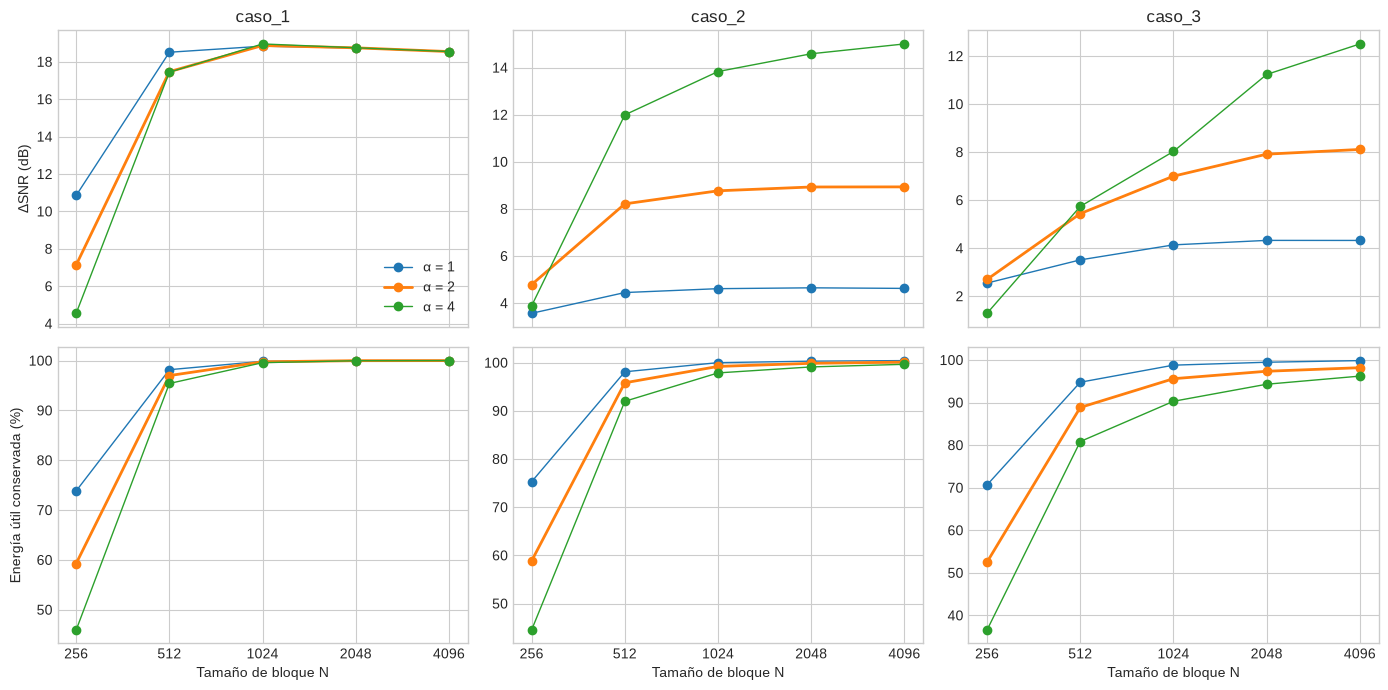

In [29]:
TAMANOS = (256, 512, 1024, 2048, 4096)
ALPHAS_COMPROBACION = (1.0, 2.0, 4.0)

filas = []
for k, cfg in CASOS.items():
    r, fs = RES[k], cfg['fs_Hz']
    util = cfg['frecuencias_utiles_Hz']
    e_ref = energia_util(r['clean'], fs, util)
    for n_blk in TAMANOS:
        pn_n, fint_n, _ = fe.estimar_ruido_e_interferencia(r['noisy'][:2 * fs], fs, n_blk)
        for a_ in ALPHAS_COMPROBACION:
            y, _ = fe.reducir_ruido_fft(r['noisy'], fs, pn_n, fint_n, n_blk, alpha=a_, g_min=G_MIN)
            filas.append({'caso': k, 'N_bloque': n_blk, 'alpha': a_,
                          'dSNR_dB': gs.snr_db(r['clean'], y) - gs.snr_db(r['clean'], r['noisy']),
                          'energia_util_conservada_%': 100 * energia_util(y, fs, util) / e_ref})
BARRIDO = pd.DataFrame(filas)

# Resolución, latencia y tiempo por bloque (no dependen de alpha ni del caso)
x_b, fs_b = RES['caso_2']['noisy'], CASOS['caso_2']['fs_Hz']
fila_n = []
for n_blk in TAMANOS:
    pn_n, fint_n, _ = fe.estimar_ruido_e_interferencia(x_b[:2 * fs_b], fs_b, n_blk)
    n_bl = fe.reducir_ruido_fft(x_b, fs_b, pn_n, fint_n, n_blk, alpha=ALPHA, g_min=G_MIN)[1].shape[0]
    t_blk = mediana_tiempo(lambda: fe.reducir_ruido_fft(x_b, fs_b, pn_n, fint_n, n_blk, alpha=ALPHA, g_min=G_MIN), repeticiones=7) / n_bl
    fila_n.append({'N_bloque': n_blk, 'delta_f_Hz': fs_b / n_blk, 'latencia_min_ms': 1e3 * n_blk / fs_b,
                   'tiempo_bloque_us': 1e6 * t_blk, 'tiempo_por_muestra_us': 1e6 * t_blk / (n_blk // 2)})
POR_N = pd.DataFrame(fila_n).set_index('N_bloque')

BARRIDO.to_csv(TESTING / 'barrido_bloque.csv', index=False)
POR_N.round(3).to_csv(TESTING / 'barrido_bloque_costos.csv')

display(BARRIDO[BARRIDO['alpha'] == ALPHA].pivot(index='N_bloque', columns='caso', values='dSNR_dB').round(2)
        .rename(columns=lambda c: f'dSNR {c} (dB)'))
display(BARRIDO[BARRIDO['alpha'] == ALPHA].pivot(index='N_bloque', columns='caso', values='energia_util_conservada_%').round(1)
        .rename(columns=lambda c: f'energía útil {c} (%)'))
display(POR_N.round(3))

fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for col, k in enumerate(CASOS):
    for a_ in ALPHAS_COMPROBACION:
        d = BARRIDO[(BARRIDO['caso'] == k) & (BARRIDO['alpha'] == a_)]
        axs[0, col].plot(d['N_bloque'], d['dSNR_dB'], 'o-', label=f'α = {a_:g}', lw=2 if a_ == ALPHA else 1)
        axs[1, col].plot(d['N_bloque'], d['energia_util_conservada_%'], 'o-', label=f'α = {a_:g}', lw=2 if a_ == ALPHA else 1)
    axs[0, col].set(title=k, ylabel='ΔSNR (dB)' if col == 0 else '')
    axs[1, col].set(xlabel='Tamaño de bloque N', ylabel='Energía útil conservada (%)' if col == 0 else '')
    axs[0, col].set_xscale('log', base=2); axs[1, col].set_xscale('log', base=2)
    axs[0, col].set_xticks(TAMANOS); axs[0, col].set_xticklabels(TAMANOS)
axs[0, 0].legend()
plt.tight_layout(); plt.savefig(FIGS / '2_5_barrido_bloque.png', dpi=150); plt.show()

### 11.5 Barrido de α (N = 1024)
El α que maximiza el ΔSNR solo se puede calcular porque se dispone de la señal limpia; un sistema real no la tiene.

In [30]:
ALPHAS_AMPLIO = (0.5, 1, 2, 3, 4, 6, 8, 12, 16, 24, 32)
filas = []
for k, cfg in CASOS.items():
    r, fs = RES[k], cfg['fs_Hz']
    util = cfg['frecuencias_utiles_Hz']
    e_ref = energia_util(r['clean'], fs, util)
    pn_a, fint_a, _ = fe.estimar_ruido_e_interferencia(r['noisy'][:2 * fs], fs, N_BLOQUE)
    for a_ in ALPHAS_AMPLIO:
        y, _ = fe.reducir_ruido_fft(r['noisy'], fs, pn_a, fint_a, N_BLOQUE, alpha=a_, g_min=G_MIN)
        filas.append({'caso': k, 'alpha': a_, 'dSNR_dB': gs.snr_db(r['clean'], y) - gs.snr_db(r['clean'], r['noisy']),
                      'energia_util_conservada_%': 100 * energia_util(y, fs, util) / e_ref})
BARRIDO_ALPHA = pd.DataFrame(filas)
BARRIDO_ALPHA.to_csv(TESTING / 'barrido_alpha.csv', index=False)

display(BARRIDO_ALPHA.pivot(index='alpha', columns='caso', values='dSNR_dB').round(2).rename(columns=lambda c: f'dSNR {c} (dB)'))
display(BARRIDO_ALPHA.pivot(index='alpha', columns='caso', values='energia_util_conservada_%').round(1).rename(columns=lambda c: f'energía útil {c} (%)'))
MEJOR_ALPHA = BARRIDO_ALPHA.loc[BARRIDO_ALPHA.groupby('caso')['dSNR_dB'].idxmax()].set_index('caso').round(2)
MEJOR_ALPHA

caso,dSNR caso_1 (dB),dSNR caso_2 (dB),dSNR caso_3 (dB)
alpha,,,
0.5,18.86,2.30,2.14
1.0,18.83,4.61,4.14
2.0,18.87,8.77,7.00
3.0,18.91,11.91,8.09
4.0,18.95,13.83,8.03
6.0,19.05,15.10,6.91
8.0,19.16,15.16,5.78
12.0,19.24,14.77,4.26
16.0,18.98,14.17,3.16


caso,energía útil caso_1 (%),energía útil caso_2 (%),energía útil caso_3 (%)
alpha,,,
0.5,99.9,100.4,100.6
1.0,99.9,100.0,98.8
2.0,99.8,99.2,95.6
3.0,99.7,98.5,92.8
4.0,99.6,97.9,90.3
6.0,99.4,96.7,86.0
8.0,99.3,95.7,82.4
12.0,99.1,93.7,77.3
16.0,98.8,91.8,74.1


,alpha,dSNR_dB,energia_util_conservada_%
caso,,,
caso_1,12.0,19.24,99.07
caso_2,8.0,15.16,95.68
caso_3,3.0,8.09,92.80
